# Phân tích các yếu tố ảnh hưởng đến rating người dùng trên MovieLens bằng cách kết hợp dữ liệu thông tin phim (TMDb)

In [3]:
import pandas as pd
import numpy as np
import re
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score, accuracy_score


In [4]:
warnings.filterwarnings('ignore')

# --- 1. ĐỊNH NGHĨA HÀM XỬ LÝ ---
def clean_movielens_title(text):
    return re.sub(r'\s*\(\d{4}\)$', '', str(text)).lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

def get_director(text):
    try:
        data = ast.literal_eval(text)
        for x in data:
            if x['job'] == 'Director': return x['name']
        return np.nan
    except: return np.nan

def get_top_actors(text):
    try:
        data = ast.literal_eval(text)
        return [x['name'] for x in data[:3]]
    except: return []

## Chuẩn bị Dữ liệu (Data Preparation)

In [5]:
# --- 2. TẢI DỮ LIỆU ---
print("Đang tải dữ liệu...")
u_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
m_cols = ['MovieID', 'Title', 'Genres']
r_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']

users = pd.read_csv('datasets/movie_len_1M/users.dat', sep='::', names=u_cols, encoding='latin-1', engine='python')
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=m_cols, encoding='latin-1', engine='python')
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=r_cols, encoding='latin-1', engine='python')

# --- TÍNH ĐIỂM TRUNG BÌNH (AVG_RATING) ---
print("Đang tính toán điểm trung bình cho từng phim...")
movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
movie_targets.columns = ['MovieID', 'avg_rating']

Đang tải dữ liệu...
Đang tính toán điểm trung bình cho từng phim...


In [6]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6040 non-null   int64 
 1   Gender      6040 non-null   object
 2   Age         6040 non-null   int64 
 3   Occupation  6040 non-null   int64 
 4   Zip-code    6040 non-null   object
dtypes: int64(3), object(2)
memory usage: 236.1+ KB


**Các ý nghĩa của từng cột trong bảng Users**:
| Cột (Column)   | Ý nghĩa |
|----------------|---------|
| **UserID**     | Mã định danh của người dùng (ID duy nhất). |
| **Gender**     | Giới tính của người dùng (M/F). |
| **Age**        | Nhóm tuổi hoặc mã tuổi của người dùng (ví dụ: 1 = dưới 18, 18, 25, 35...). |
| **Occupation** | Mã nghề nghiệp của người dùng (một số nguyên biểu diễn từng loại nghề khác nhau). |
| **Zip-code**   | Mã bưu điện (ZIP) hoặc khu vực mà người dùng sinh sống. |


In [7]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   MovieID  3883 non-null   int64 
 1   Title    3883 non-null   object
 2   Genres   3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB


**Các ý nghĩa của từng cột trong bảng Movies**:
| Cột (Column) | Ý nghĩa |
|--------------|---------|
| **MovieID**  | ID duy nhất của phim trong hệ thống MovieLens. |
| **Title**    | Tên phim kèm năm phát hành (ví dụ: *Toy Story (1995)*). |
| **Genres**   | Các thể loại phim, phân tách bằng dấu `|` (ví dụ: *Animation|Children's|Comedy*). |


In [8]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-null  int64
 1   MovieID    1000209 non-null  int64
 2   Rating     1000209 non-null  int64
 3   Timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB


**Các ý nghĩa của từng cột trong bảng Ratings**:
| Cột (Column) | Ý nghĩa |
|--------------|---------|
| **UserID**   | ID người dùng đã đánh giá phim. |
| **MovieID**  | ID của bộ phim được đánh giá. |
| **Rating**   | Điểm đánh giá do người dùng chấm (thường từ 1 đến 5). |
| **Timestamp**| Thời điểm đánh giá (dạng UNIX timestamp – số giây tính từ 1/1/1970). |


In [9]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB ---
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

tmdb_cred.columns = ['movie_id', 'title', 'cast', 'crew']
tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

print(f"Loaded & Merged TMDB: {tmdb_full.shape}")

Loaded & Merged TMDB: (4803, 23)


In [10]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

**Giải thích ý nghĩa của các cột**
| Cột (Column)           | Ý nghĩa |
|------------------------|---------|
| **budget**             | Ngân sách sản xuất phim (USD). |
| **genres**             | Thể loại phim, lưu dưới dạng chuỗi JSON (Action, Comedy…). |
| **homepage**           | Trang web chính thức của bộ phim. |
| **movie_id**           | ID phim trong cơ sở dữ liệu TheMovieDB. |
| **keywords**           | Các từ khóa mô tả nội dung phim. |
| **original_language**  | Ngôn ngữ gốc của phim (ví dụ: `en`, `fr`). |
| **original_title**     | Tên gốc của bộ phim. |
| **overview**           | Tóm tắt nội dung phim. |
| **popularity**         | Mức độ phổ biến của phim trên TMDB. |
| **production_companies** | Danh sách công ty sản xuất phim (JSON string). |
| **production_countries** | Danh sách quốc gia sản xuất phim. |
| **release_date**       | Ngày phát hành phim. |
| **revenue**            | Doanh thu phòng vé (USD). |
| **runtime**            | Thời lượng phim (phút). |
| **spoken_languages**   | Danh sách ngôn ngữ được sử dụng trong phim. |
| **status**             | Tình trạng phát hành (Released, Post Production…). |
| **tagline**            | Slogan/tagline của phim. |
| **title**              | Tên phim phát hành chính thức. |
| **vote_average**       | Điểm đánh giá trung bình trên TMDB. |
| **vote_count**         | Số lượt đánh giá. |
| **tittle_credits**     | Thông tin credit khi merge, có thể là lỗi chính tả của `title_credits`. |
| **cast**               | Danh sách diễn viên của phim (JSON string). |
| **crew**               | Danh sách nhân sự (đạo diễn, biên kịch…) của phim (JSON string). |


In [11]:

# --- 3. HIỂN THỊ DỮ LIỆU MẪU ĐỂ KIỂM TRA ---

print("\n--- Sample Users ---")
users.head(3)


--- Sample Users ---


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


In [12]:
print("\n--- Sample Movies ---")
movies.head(3)


--- Sample Movies ---


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


In [13]:
print("\n--- Sample Ratings ---")
ratings.head(3)


--- Sample Ratings ---


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


In [14]:
print("\n--- Sample TMDB Credits ---")
tmdb_cred.head(3)


--- Sample TMDB Credits ---


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


In [15]:
print("\n--- Sample TMDB Movies ---")
tmdb_mov.head(3)


--- Sample TMDB Movies ---


,budget,genres,homepage,movie_id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


## Tiền xử lý dữ liệu (Data Preprocessing)

### Chuẩn hóa (Data Normalization)

In [16]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB (SỬA LẠI ĐỂ TRÁNH LỖI TITLE) ---
print("Đang tải và xử lý TMDB...")
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

# --- ĐIỂM SỬA QUAN TRỌNG TẠI ĐÂY ---
# Đổi tên cột title của credits thành 'tittle_cr' để không trùng với 'title' của bảng movies
tmdb_cred.columns = ['movie_id', 'tittle_cr', 'cast', 'crew']

tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})

# Merge nội bộ TMDB
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

# Kiểm tra xem cột title có tồn tại không
if 'title' not in tmdb_full.columns:
    # Trường hợp file gốc dùng 'original_title', ta tạo lại cột title
    if 'original_title' in tmdb_full.columns:
        tmdb_full['title'] = tmdb_full['original_title']

print(f"Cột trong TMDB Full: {list(tmdb_full.columns)}")
# Bây giờ chắc chắn đã có cột 'title'

# --- 4. MERGE METADATA (CHẠY LẠI BƯỚC NÀY SẼ KHÔNG CÒN LỖI) ---
print("Đang xử lý Metadata phim...")

# Tạo khóa nối
movies['title_join'] = movies['Title'].apply(clean_movielens_title)
tmdb_full['title_join'] = tmdb_full['title'].apply(clean_tmdb_title)

# Ghép Movies gốc với TMDB
movies_meta = pd.merge(movies, tmdb_full, on='title_join', how='inner')

# Ghép thêm cột avg_rating (từ bảng movie_targets đã tạo ở bước trước)
movies_meta = pd.merge(movies_meta, movie_targets, on='MovieID', how='inner')

# Trích xuất Director, Actors, Year
movies_meta['director'] = movies_meta['crew'].apply(get_director)
movies_meta['actors_temp'] = movies_meta['cast'].apply(get_top_actors)
actors_df = movies_meta['actors_temp'].apply(pd.Series).iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']
movies_meta = pd.concat([movies_meta, actors_df], axis=1)
movies_meta['release_year'] = movies_meta['Title'].str.extract(r'\((\d{4})\)$').astype(float)

# Chọn lọc các cột metadata
cols_meta = [
    'MovieID', 'Title', 'Genres', 'release_year', 'avg_rating',
    'director', 'actor_1', 'actor_2', 'actor_3',
    'budget', 'revenue', 'vote_average', 'vote_count', 'runtime'
]
movies_final_meta = movies_meta[cols_meta]

# --- 5. TẠO DATAFRAME CUỐI CÙNG ---
print("Đang ghép vào bảng Ratings gốc...")
df_final = pd.merge(ratings, movies_final_meta, on='MovieID', how='inner')

print("-" * 30)
print(f"Kích thước cuối cùng: {df_final.shape}")
print("5 dòng đầu tiên:")
print(df_final[['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average']].head())

Đang tải và xử lý TMDB...
Cột trong TMDB Full: ['budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew']
Đang xử lý Metadata phim...
Đang ghép vào bảng Ratings gốc...
------------------------------
Kích thước cuối cùng: (450575, 17)
5 dòng đầu tiên:
   UserID                                   Title  Rating  avg_rating  \
0       1  One Flew Over the Cuckoo's Nest (1975)       5    4.390725   
1       1                     My Fair Lady (1964)       3    4.154088   
2       1                  Erin Brockovich (2000)       4    3.863878   
3       1                          Ben-Hur (1959)       5    4.110795   
4       1  Snow White and the Seven Dwarfs (1937)       4    3.845347   

   vote_average  
0           8.2  
1           7.4 

### Trích xuất đặc trưng (Feature Selection)

In [17]:
movies_merged = movies_meta.copy()

# --- 2. ÁP DỤNG VÀO DATAFRAME ---
print("Đang trích xuất dữ liệu Đạo diễn, Diễn viên và Năm phát hành...")

# 1. Reset các cột nếu đã lỡ chạy trước đó (để tránh lỗi duplicate columns)
cols_to_reset = ['director', 'actor_1', 'actor_2', 'actor_3', 'actors_list', 'release_year']
movies_merged = movies_merged.drop(columns=[c for c in cols_to_reset if c in movies_merged.columns], errors='ignore')

# 2. Trích xuất Đạo diễn (Director)
# Lưu ý: Hàm get_director phải được định nghĩa từ trước
movies_merged['director'] = movies_merged['crew'].apply(get_director)

# 3. Trích xuất Diễn viên (Actors) - CÁCH TỐI ƯU & AN TOÀN HƠN
# Lấy list diễn viên
movies_merged['actors_list'] = movies_merged['cast'].apply(get_top_actors)

# Tách list thành các cột riêng biệt
actors_df = movies_merged['actors_list'].apply(pd.Series)

# Đảm bảo luôn có đủ 3 cột (0, 1, 2) dù dữ liệu thiếu
for i in range(3):
    if i not in actors_df.columns:
        actors_df[i] = np.nan

# Chỉ lấy 3 cột đầu tiên và đổi tên
actors_df = actors_df.iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']

# Ghép vào bảng chính
movies_merged = pd.concat([movies_merged, actors_df], axis=1)

# 4. Trích xuất Năm phát hành (Release Year) từ Title của MovieLens
# Regex: Tìm 4 số nằm trong ngoặc đơn ở cuối chuỗi
movies_merged['release_year'] = movies_merged['Title'].str.extract(r'\((\d{4})\)$')
movies_merged['release_year'] = pd.to_numeric(movies_merged['release_year'], errors='coerce')

# 5. Dọn dẹp cột tạm
movies_merged = movies_merged.drop(columns=['actors_list'], errors='ignore')

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print("Các cột hiện có sau khi xử lý Feature Engineering:")
print(list(movies_merged.columns))

print("\n5 dòng dữ liệu mẫu (Kiểm tra Đạo diễn, Diễn viên, Năm):")
cols_check = ['Title', 'release_year', 'director', 'actor_1', 'Genres']
print(movies_merged[cols_check].head())

Đang trích xuất dữ liệu Đạo diễn, Diễn viên và Năm phát hành...
------------------------------
Các cột hiện có sau khi xử lý Feature Engineering:
['MovieID', 'Title', 'Genres', 'title_join', 'budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew', 'avg_rating', 'actors_temp', 'director', 'actor_1', 'actor_2', 'actor_3', 'release_year']

5 dòng dữ liệu mẫu (Kiểm tra Đạo diễn, Diễn viên, Năm):
                     Title  release_year         director          actor_1  \
0         Toy Story (1995)          1995    John Lasseter        Tom Hanks   
1         GoldenEye (1995)          1995  Martin Campbell   Pierce Brosnan   
2             Nixon (1995)          1995     Oliver Stone  Anthony Hopkins   
3  Cutthroat Island (1995)        

### Tích hợp dữ liệu (Data Integration)

In [18]:
# --- TỐI ƯU HÓA TRƯỚC KHI MERGE ---

# 1. Chọn lọc các cột cần thiết từ bảng phim (Metadata)
# Chúng ta chỉ giữ lại những thông tin có giá trị phân tích
cols_to_keep = [
    'MovieID', 'Title',             # Định danh phim
    'Genres', 'release_year', 'runtime' ,     # Thông tin cơ bản
    'director', 'actor_1', 'actor_2', 'actor_3', # Ekip làm phim
    'budget', 'revenue',            # Tài chính
    'vote_average', 'vote_count',   # Đánh giá từ TMDB
    'avg_rating'                    # Đánh giá trung bình từ MovieLens (Đã tính ở bước trước)
]

# Lọc để chỉ lấy các cột thực sự tồn tại trong movies_merged (tránh lỗi nếu thiếu cột nào đó)
existing_cols = [c for c in cols_to_keep if c in movies_merged.columns]
movies_lean = movies_merged[existing_cols]

# 2. Thực hiện Merge cuối cùng (Big Merge)
# Ghép bảng Ratings (1 triệu dòng) với bảng Metadata phim đã lọc gọn
# Dùng 'inner' để chỉ giữ lại các rating của những phim ĐÃ CÓ thông tin từ TMDB
print("Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...")
full_data = pd.merge(ratings, movies_lean, on='MovieID', how='inner')

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print(f"Tổng số lượt đánh giá gốc (Ratings): {ratings.shape[0]}")
print(f"Tổng số dòng dữ liệu sau khi merge (Full Data): {full_data.shape[0]}")
print(f"-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): {ratings.shape[0] - full_data.shape[0]}")
print("-" * 30)

# Xem 5 dòng dữ liệu hoàn chỉnh để đảm bảo bạn có đủ 3 loại điểm số
# 1. Rating: Điểm do người dùng này chấm
# 2. avg_rating: Điểm trung bình của phim trên MovieLens
# 3. vote_average: Điểm trung bình của phim trên TMDB
print("5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):")
cols_check = ['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average', 'director']
print(full_data[cols_check].head())

Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...
------------------------------
Tổng số lượt đánh giá gốc (Ratings): 1000209
Tổng số dòng dữ liệu sau khi merge (Full Data): 450575
-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): 549634
------------------------------
5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):
   UserID                                   Title  Rating  avg_rating  \
0       1  One Flew Over the Cuckoo's Nest (1975)       5    4.390725   
1       1                     My Fair Lady (1964)       3    4.154088   
2       1                  Erin Brockovich (2000)       4    3.863878   
3       1                          Ben-Hur (1959)       5    4.110795   
4       1  Snow White and the Seven Dwarfs (1937)       4    3.845347   

   vote_average           director  
0           8.2       Miloš Forman  
1           7.4       George Cukor  
2           7.1  Steven Soderbergh  
3           5.3  Timur Bekmambetov  
4           6.9         David Hand  


In [19]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450575 entries, 0 to 450574
Data columns (total 17 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   UserID        450575 non-null  int64  
 1   MovieID       450575 non-null  int64  
 2   Rating        450575 non-null  int64  
 3   Timestamp     450575 non-null  int64  
 4   Title         450575 non-null  object 
 5   Genres        450575 non-null  object 
 6   release_year  450575 non-null  int64  
 7   runtime       450575 non-null  float64
 8   director      450535 non-null  object 
 9   actor_1       450535 non-null  object 
 10  actor_2       450535 non-null  object 
 11  actor_3       450535 non-null  object 
 12  budget        450575 non-null  int64  
 13  revenue       450575 non-null  int64  
 14  vote_average  450575 non-null  float64
 15  vote_count    450575 non-null  int64  
 16  avg_rating    450575 non-null  float64
dtypes: float64(3), int64(8), object(6)
memory usage:

In [20]:
full_data.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,runtime,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,133.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,131.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347
5,1,2791,4,978302188,Airplane! (1980),Comedy,1980,88.0,Jerry Zucker,Robert Hays,Julie Hagerty,Kareem Abdul-Jabbar,3500000,83453539,7.1,1074,3.971115
6,1,2018,4,978301777,Bambi (1942),Animation|Children's,1942,70.0,David Hand,Donnie Dunagan,Peter Behn,Stan Alexander,858000,267447150,6.8,1405,3.738540
7,1,2797,4,978302039,Big (1988),Comedy|Fantasy,1988,104.0,Penny Marshall,Tom Hanks,Elizabeth Perkins,Robert Loggia,18000000,151668774,6.9,993,3.855801
8,1,1270,5,978300055,Back to the Future (1985),Comedy|Sci-Fi,1985,116.0,Robert Zemeckis,Michael J. Fox,Christopher Lloyd,Lea Thompson,19000000,381109762,8.0,6079,3.990321
9,1,527,5,978824195,Schindler's List (1993),Drama|War,1993,195.0,Steven Spielberg,Liam Neeson,Ben Kingsley,Ralph Fiennes,22000000,321365567,8.3,4329,4.510417


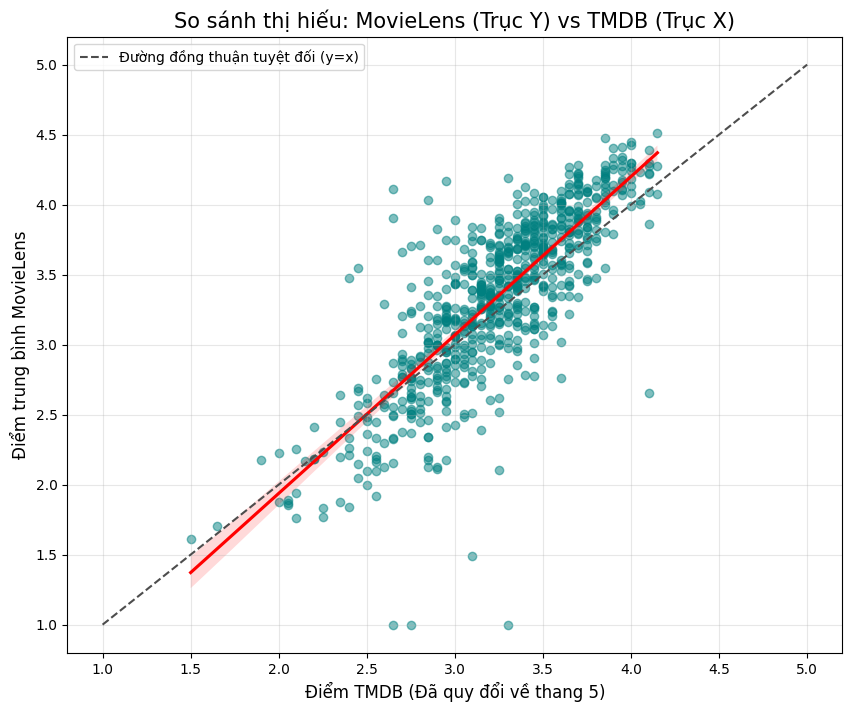

--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
95              Ben-Hur (1959)  4.110795             2.65
347        Ghostbusters (1984)  3.905548             2.65
701     Shall We Dance? (1937)  4.165714             2.95
29   All the King's Men (1949)  4.033613             2.85
369  Gulliver's Travels (1939)  3.547009             2.45

--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
834          Underworld (1997)  1.000000             3.30
342         Get Over It (1996)  1.000000             2.75
718           Sleepover (1995)  1.000000             2.65
222  Digimon: The Movie (2000)  1.488372             3.10
628              Psycho (1998)  2.651515             4.10


In [21]:
# --- BƯỚC 1: GOM NHÓM DỮ LIỆU THEO PHIM ---
# Tính điểm trung bình thực tế của người dùng MovieLens cho từng phim
movie_comparison = full_data.groupby('Title').agg({
    'Rating': 'mean',          # Điểm trung bình MovieLens (1-5)
    'vote_average': 'first',   # Điểm TMDB (0-10) - Lấy giá trị đầu tiên vì nó giống nhau cho cả phim
    'vote_count': 'first'   # Lấy số lượng vote để lọc bớt phim ít người xem
}).reset_index()

# Đổi tên cho dễ gọi
movie_comparison.columns = ['Title', 'ML_Score', 'TMDB_Score', 'Vote_Count']

# --- BƯỚC 2: CHUẨN HÓA THANG ĐIỂM ---
# Chuyển TMDB từ thang 10 về thang 5 để so sánh công bằng
movie_comparison['TMDB_Score_Norm'] = movie_comparison['TMDB_Score'] / 2

# Lọc các phim có ít nhất 50 lượt đánh giá để biểu đồ không bị nhiễu
movie_comparison = movie_comparison[movie_comparison['Vote_Count'] > 50]

# --- BƯỚC 3: VẼ BIỂU ĐỒ TƯƠNG QUAN ---
plt.figure(figsize=(10, 8))

# Vẽ Scatter plot kèm đường hồi quy (Regplot)
sns.regplot(x='TMDB_Score_Norm', y='ML_Score', data=movie_comparison,
            scatter_kws={'alpha': 0.5, 'color': 'teal'},
            line_kws={'color': 'red'})

# Vẽ đường chéo y=x (Đường tham chiếu sự hoàn hảo)
# Nếu điểm nằm trên đường này: MovieLens và TMDB chấm y hệt nhau
plt.plot([1, 5], [1, 5], ls="--", c=".3", label="Đường đồng thuận tuyệt đối (y=x)")

plt.title('So sánh thị hiếu: MovieLens (Trục Y) vs TMDB (Trục X)', fontsize=15)
plt.xlabel('Điểm TMDB (Đã quy đổi về thang 5)', fontsize=12)
plt.ylabel('Điểm trung bình MovieLens', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- BƯỚC 4: TÌM NHỮNG PHIM "GÂY TRANH CÃI" NHẤT ---
# Tính độ lệch (Gap)
movie_comparison['Diff'] = movie_comparison['ML_Score'] - movie_comparison['TMDB_Score_Norm']

print("--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=False)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

print("\n--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=True)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

### Làm sạch dữ liệu (Data Cleaning)

In [22]:
# Kiểm tra dữ liệu bị thiếu (Missing values)
full_data.isnull().sum()

UserID           0
MovieID          0
Rating           0
Timestamp        0
Title            0
Genres           0
release_year     0
runtime          0
director        40
actor_1         40
actor_2         40
actor_3         40
budget           0
revenue          0
vote_average     0
vote_count       0
avg_rating       0
dtype: int64

In [23]:
# XỬ LÝ DỮ LIỆU BỊ THIẾU (XÓA DÒNG)
# inplace=True sẽ thay đổi trực tiếp trên dataframe hiện tại
full_data.dropna(subset=['director', 'actor_1'], inplace=True)

print(f"Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: {full_data.shape}\n Số dòng bị thiếu: \n{full_data.isnull().sum()}")

Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: (450495, 17)
 Số dòng bị thiếu: 
UserID          0
MovieID         0
Rating          0
Timestamp       0
Title           0
Genres          0
release_year    0
runtime         0
director        0
actor_1         0
actor_2         0
actor_3         0
budget          0
revenue         0
vote_average    0
vote_count      0
avg_rating      0
dtype: int64


In [24]:
# Kiểm tra dữ liệu bị trùng lặp
full_data.duplicated().sum()

0

In [25]:
# --- LỌC DỮ LIỆU CHẤT LƯỢNG CAO (CLEANING DATA) ---

print(f"Số lượng dòng dữ liệu ban đầu: {full_data.shape[0]}")

# Áp dụng 3 điều kiện lọc cùng lúc:
# 1. vote_count > 50: Bỏ qua các phim quá ít người quan tâm trên TMDB (tránh nhiễu)
# 2. budget > 10000: Bỏ qua phim không có số liệu ngân sách hoặc ngân sách quá thấp (lỗi nhập liệu)
# 3. revenue > 10000: Bỏ qua phim không có số liệu doanh thu

full_data = full_data[
    (full_data['vote_count'] > 50) &
    (full_data['budget'] > 10000) &
    (full_data['revenue'] > 10000)
]

# --- KIỂM TRA KẾT QUẢ SAU KHI LỌC ---
print("-" * 30)
print(f"Số lượng dòng sau khi lọc: {full_data.shape[0]}")
print(f"-> Đã loại bỏ: {full_data.shape[0] - full_data.shape[0]} dòng dữ liệu rác/thiếu thông tin.")

# Xem thống kê nhanh về tài chính của tập dữ liệu sạch
print("\nThống kê dữ liệu tài chính sau khi lọc:")
print(full_data[['budget', 'revenue', 'vote_count']].describe().apply(lambda s: s.apply('{0:.2f}'.format)))

Số lượng dòng dữ liệu ban đầu: 450495
------------------------------
Số lượng dòng sau khi lọc: 397975
-> Đã loại bỏ: 0 dòng dữ liệu rác/thiếu thông tin.

Thống kê dữ liệu tài chính sau khi lọc:
             budget        revenue vote_count
count     397975.00      397975.00  397975.00
mean    37087587.03   180600388.37    1467.37
std     36699190.83   210367425.44    1606.35
min        12000.00      120000.00      52.00
25%     10500000.00    39846344.00     395.00
50%     25000000.00   115101622.00     840.00
75%     55000000.00   254700832.00    1783.00
max    207000000.00  1845034188.00    9413.00


## Khám phá Dữ liệu (EDA - Exploratory Data Analysis)

In [26]:
full_data.describe().T.style.format("{:.2f}").background_gradient(cmap = "magma")

,count,mean,std,min,25%,50%,75%,max
UserID,397975.00,3005.05,1729.01,1.00,1496.00,3038.00,4451.00,6040.00
MovieID,397975.00,1796.27,1071.55,1.00,1028.00,1676.00,2699.00,3949.00
Rating,397975.00,3.63,1.11,1.00,3.00,4.00,4.00,5.00
Timestamp,397975.00,972107846.17,11854877.66,956703954.00,965306212.00,973051290.00,975200680.50,1046454443.00
release_year,397975.00,1988.62,12.98,1926.00,1984.00,1994.00,1997.00,2000.00
runtime,397975.00,118.22,23.99,70.00,102.00,116.00,128.00,238.00
budget,397975.00,37087587.03,36699190.83,12000.00,10500000.00,25000000.00,55000000.00,207000000.00
revenue,397975.00,180600388.37,210367425.44,120000.00,39846344.00,115101622.00,254700832.00,1845034188.00
vote_average,397975.00,6.86,0.80,3.00,6.40,6.90,7.50,8.30
vote_count,397975.00,1467.37,1606.35,52.00,395.00,840.00,1783.00,9413.00


Sau bước làm sạch dữ liệu, bộ dữ liệu còn 397.975 bản ghi — vẫn là một quy mô rất lớn, đảm bảo độ tin cậy cho các phân tích tiếp theo. Việc loại bỏ các giá trị nhiễu và thiếu thông tin đã giúp dữ liệu phản ánh sát hơn thực tế thị trường và hành vi người xem.

Đối với dữ liệu đánh giá, điểm Rating trung bình tăng nhẹ lên 3.63 trong khi trung vị vẫn giữ ở mức 4.0. Điều này cho thấy mức độ hài lòng chung có xu hướng tích cực hơn sau khi loại bỏ các phim ít người xem hoặc chất lượng thấp. Đặc biệt, số lượng tối thiểu lượt đánh giá hiện là 52, thay vì 0 như trước. Điều này đảm bảo rằng mỗi bộ phim trong dữ liệu đều đã nhận được đánh giá từ ít nhất 52 người, từ đó tăng tính đáng tin cậy của dữ liệu và hạn chế hiện tượng đánh giá sai lệch.

Ở khía cạnh tài chính, phân phối của ngân sách và doanh thu thể hiện rõ dạng lệch phải, đặc trưng phổ biến của ngành điện ảnh. Ngân sách trung bình khoảng 37 triệu USD, cao hơn đáng kể so với trung vị 25 triệu USD. Doanh thu cũng cho thấy sự chênh lệch lớn khi trung bình đạt 180 triệu USD trong khi trung vị chỉ khoảng 115 triệu USD. Điều này chứng minh sự tồn tại của nhóm phim bom tấn — tuy chiếm tỷ lệ nhỏ nhưng có sức ảnh hưởng mạnh, làm kéo mức trung bình lên cao. Hơn nữa, việc các giá trị tài chính nhỏ nhất đã được làm sạch và không còn dạng phi thực tế như 0 USD giúp các phân tích tiếp theo trở nên chính xác và hợp lý hơn.

Cuối cùng, dữ liệu thời gian trải dài từ năm 1926 đến 2000, phản ánh một giai đoạn phát triển dài của ngành công nghiệp điện ảnh. Trung bình năm phát hành rơi vào khoảng 1989, cho thấy phần lớn các phim trong mẫu là phim hiện đại, gần với thị hiếu và thói quen xem phim của người dùng MovieLens. Điều này cũng đồng nghĩa rằng các phân tích tiếp theo mang tính đại diện cao đối với xu hướng thị trường giải trí cuối thế kỷ 20.

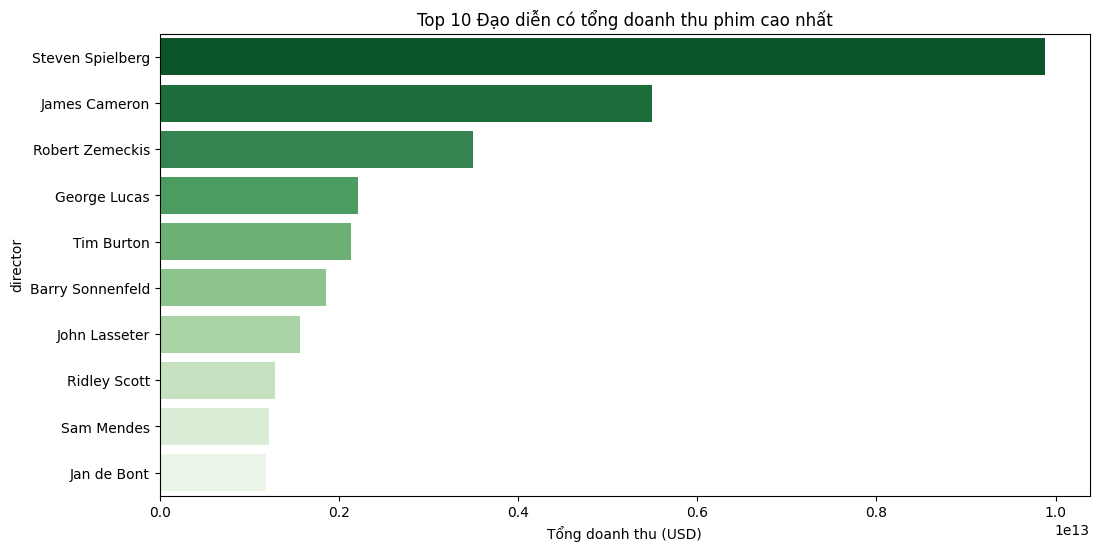

In [27]:
# Gom nhóm theo Đạo diễn và tính tổng doanh thu
# Chỉ lấy những dòng có revenue (tự động bỏ NaN)
director_revenue = full_data.groupby('director')['revenue'].sum().sort_values(ascending=False).head(10)

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))
sns.barplot(x=director_revenue.values, y=director_revenue.index, palette='Greens_r')
plt.title('Top 10 Đạo diễn có tổng doanh thu phim cao nhất')
plt.xlabel('Tổng doanh thu (USD)')
plt.show()

Biểu đồ thanh ngang minh họa Top 10 đạo diễn dẫn đầu về tổng doanh thu phòng vé trong tập dữ liệu, cho thấy sự phân hóa mạnh mẽ về hiệu suất thương mại giữa các nhà làm phim hàng đầu. Nổi bật nhất là sự thống trị tuyệt đối của Steven Spielberg với tổng doanh thu tiệm cận mốc 10 tỷ USD. Cột dữ liệu của ông dài vượt trội, gần gấp đôi so với người đứng thứ hai, khẳng định vị thế "Vua phòng vé" và khả năng tạo ra các tác phẩm đại chúng xuyên suốt nhiều thập kỷ.

Đứng ở vị trí thứ hai là James Cameron với tổng doanh thu đạt khoảng hơn 5.5 tỷ USD. Mặc dù số lượng phim của ông thường ít hơn Spielberg, nhưng hiệu suất doanh thu trên từng đầu phim (như Titanic, Avatar) là cực kỳ lớn giúp ông giữ vững vị trí á quân. Theo sau là Robert Zemeckis ở vị trí thứ ba với khoảng 3.5 tỷ USD, đại diện cho nhóm đạo diễn gạo cội có phong cách làm phim ăn khách bền vững.

Nhóm các đạo diễn còn lại như George Lucas và Tim Burton duy trì mức doanh thu ổn định trong khoảng hơn 2 tỷ USD. Nửa dưới của Top 10 bao gồm Barry Sonnenfeld, John Lasseter, Ridley Scott, Sam Mendes và Jan de Bont với mức doanh thu dao động từ 1.2 đến 1.8 tỷ USD. Nhìn chung, biểu đồ phản ánh rõ quy luật "Winner-takes-all" trong ngành công nghiệp điện ảnh, nơi một nhóm nhỏ các đạo diễn siêu sao (Tier 1) nắm giữ phần lớn thị phần doanh thu so với phần còn lại của thị trường.

#### Phân tích biến mục tiêu Rating
1. Phân tích đơn biến

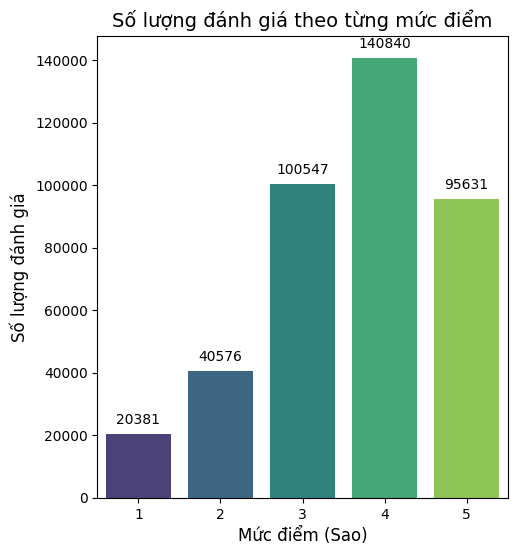

In [28]:
# Thiết lập kích thước tổng thể
plt.figure(figsize=(18, 6))

# --- BIỂU ĐỒ 1: PHÂN PHỐI SỐ LƯỢNG (COUNT PLOT) ---
# Giúp bạn thấy rõ số lượng đánh giá cho từng mức điểm (1-5 sao)
plt.subplot(1, 3, 1)
ax = sns.countplot(x='Rating', data=full_data, palette='viridis')
plt.title('Số lượng đánh giá theo từng mức điểm', fontsize=14)
plt.xlabel('Mức điểm (Sao)', fontsize=12)
plt.ylabel('Số lượng đánh giá', fontsize=12)

# Thêm số liệu cụ thể lên đầu cột để dễ đọc
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points')

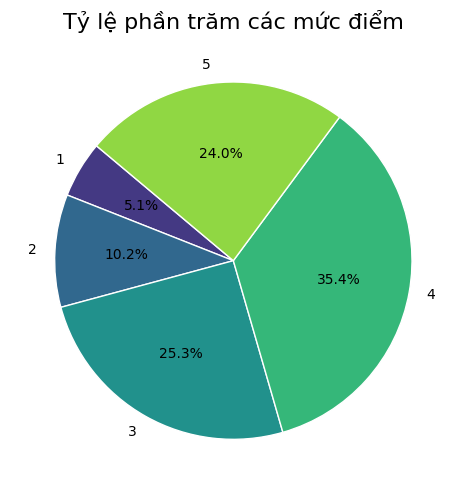

In [29]:
# --- BIỂU ĐỒ 2: TỶ TRỌNG PHẦN TRĂM (PIE CHART) ---
plt.figure(figsize=(14, 5))   # ⬅ tăng kích thước toàn hình

plt.subplot(1, 3, 2)
rating_counts = full_data['Rating'].value_counts().sort_index()

plt.pie(
    rating_counts,
    labels=rating_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('viridis', 5),
    wedgeprops={'edgecolor': 'white'}
)

plt.title('Tỷ lệ phần trăm các mức điểm', fontsize=16)  # tăng font luôn
plt.tight_layout()


In [30]:
fig = px.histogram(full_data,x='Rating',
                   labels={'Rating': 'Điểm số', 'count': 'Số lượng'},
                   title="Biểu đồ phân phối điểm số")
fig.update_yaxes(title="Số lượng")
fig.update_traces(
    hovertemplate="Điểm số = %{x}<br>Số lượng = %{y}"
)
fig.show()

Dựa trên biểu đồ phân phối số lượng đánh giá theo từng mức điểm, có thể nhận định rằng dữ liệu mang tính lệch trái rõ rệt, khi phần lớn người dùng tập trung chấm điểm cao. Cụ thể, mức điểm 4 sao xuất hiện nhiều nhất, chiếm hơn 140 nghìn lượt đánh giá, tiếp theo là 5 sao với hơn 95 nghìn lượt. Trong khi đó, các mức điểm thấp (1–2 sao) xuất hiện rất ít. Điều này cho thấy xu hướng đánh giá tích cực là chủ đạo.

Kết quả này phản ánh đúng tâm lý người dùng trong hệ thống đánh giá phim: họ có xu hướng xem những bộ phim phù hợp với sở thích nên thường cho điểm cao. Ngược lại, các bộ phim dở hoặc không phù hợp thường bị bỏ dở, dẫn đến việc người xem không đánh giá hoặc không chấm quá thấp. Vì vậy, điểm 3 sao không thực sự đại diện mức trung bình, mà mang ý nghĩa thiên về mức "trung bình thấp". Một bộ phim muốn được xem là “hay” cần đạt mức 4–5 sao.

In [31]:
# --- IN RA CON SỐ THỐNG KÊ CỤ THỂ ---
mean_rating = full_data['Rating'].mean()
median_rating = full_data['Rating'].median()
print(f"Điểm đánh giá trung bình (Mean): {mean_rating:.2f}")
print(f"Điểm đánh giá trung vị (Median): {median_rating}")

Điểm đánh giá trung bình (Mean): 3.63
Điểm đánh giá trung vị (Median): 4.0


Hai giá trị Mean = 3.63 và Median = 4.0 cho thấy người dùng có xu hướng chấm điểm khá cao cho các bộ phim. Việc trung vị (4.0) lớn hơn trung bình (3.63) chứng tỏ phần lớn đánh giá tập trung ở mức tốt (4–5 sao), trong khi một số ít đánh giá thấp đã kéo trung bình giảm xuống. Trong trường hợp này, Median = 4.0 là giá trị đáng tin cậy hơn để đại diện cho mức độ hài lòng thực tế, vì nó phản ánh điểm điển hình mà phần lớn người dùng chấm, thay vì bị ảnh hưởng bởi một số ít đánh giá cực thấp. Do đó, khi đánh giá chất lượng phim của dataset, mức điểm phổ biến và đáng tin nhất chính là 4 sao.

2. Phân tích đa biến

Trả lời câu hỏi: "Phim càng nhiều người chấm điểm (càng nổi) thì điểm càng cao, hay phim "bom xịt" mới ít người chấm?" thông qua mối tương quan giữa "Độ nổi tiếng" và "Chất lượng"


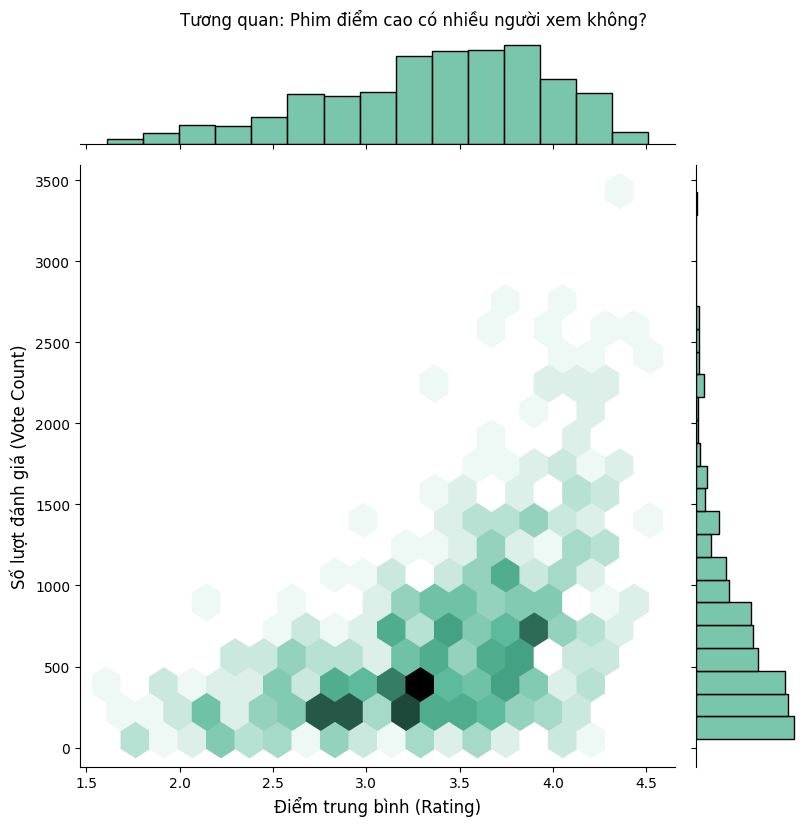

In [32]:
# Biểu đồ Joint Plot: Tương quan giữa "Độ nổi tiếng" và "Chất lượng"
# Tạo một biến đếm số lượng rating cho mỗi phim (Vote Count)
movie_stats = full_data.groupby('Title').agg({'Rating': ['mean', 'count']})
movie_stats.columns = ['avg_rating', 'vote_count']

# Lọc bớt các phim quá ít rating (< 50) để biểu đồ đỡ nhiễu
popular_movies = movie_stats[movie_stats['vote_count'] > 50]

# Vẽ Jointplot kiểu 'hex' (tổ ong) nhìn rất ngầu
# kind='hex' giúp nhìn rõ mật độ tập trung hơn là scatter chấm bi thông thường
g = sns.jointplot(x='avg_rating', y='vote_count', data=popular_movies,
                  kind='hex', color='#4CB391', height=8)

g.fig.suptitle('Tương quan: Phim điểm cao có nhiều người xem không?', y=1.02)
g.set_axis_labels('Điểm trung bình (Rating)', 'Số lượt đánh giá (Vote Count)', fontsize=12)
plt.show()

Biểu đồ Jointplot (dạng tổ ong) cung cấp một góc nhìn sâu sắc về quy luật đào thải của điện ảnh. Phần lớn các điểm dữ liệu tập trung ở vùng điểm trung bình (3.0 - 3.5) với số lượng đánh giá thấp, phản ánh thực tế rằng đa số các bộ phim đều ở mức thường thường bậc trung và ít được chú ý. Tuy nhiên, khi quan sát các bộ phim có lượng tương tác "khủng" (trên 2000 lượt đánh giá), chúng ta thấy chúng hầu hết đều nằm ở vùng điểm số cao (trên 3.5). Hiện tượng này khẳng định mối tương quan thuận chiều giữa chất lượng và độ nổi tiếng: phim dở thường bị lãng quên nhanh chóng, trong khi chỉ những tác phẩm thực sự chất lượng mới đủ sức tạo ra hiệu ứng đám đông và thu hút lượng người xem lớn.

Trả lời câu hỏi: Đàn ông và Phụ nữ, ai "khắt khe" hơn khi chấm điểm? Boxplot bình thường không cho thấy mật độ, nhưng Violin plot thì có.

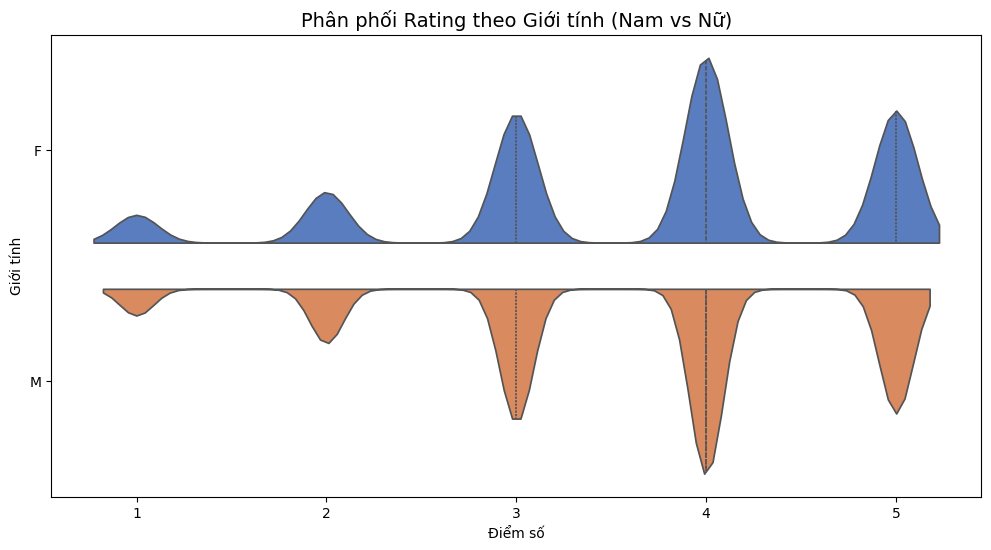

In [33]:
# Biểu đồ Violin Plot: So sánh Rating theo Giới tính/Độ tuổi
full_data = pd.merge(full_data, users[['UserID', 'Gender', 'Age']], on='UserID', how='left')
plt.figure(figsize=(12, 6))

# Vẽ Violin plot
# split=True: Chia đôi cây đàn, một nửa là Nam (M), một nửa là Nữ (F) để dễ so sánh
sns.violinplot(x='Rating', y='Gender', data=full_data,
               palette='muted', split=True, inner='quartile')

plt.title('Phân phối Rating theo Giới tính (Nam vs Nữ)', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Giới tính')
plt.show()

Về sự khác biệt hành vi giữa các nhóm giới tính Biểu đồ Violin (Violin Plot) cung cấp cái nhìn so sánh thú vị giữa người dùng Nam và Nữ. Mặc dù hình dáng phân phối tổng thể khá tương đồng (đều phình to ở mức 3-4 sao), nhưng có những sự khác biệt tinh tế. Nhóm người dùng Nữ thể hiện sự quyết đoán và hào phóng hơn, biểu hiện qua phần đỉnh nhọn và phình to hơn ở mức 4-5 sao. Trong khi đó, nhóm Nam giới có phổ đánh giá trải rộng hơn một chút xuống các mức điểm thấp (2-3 sao). Tuy nhiên, kết luận chung là giới tính không phải yếu tố gây phân cực sâu sắc về điểm số; cả hai giới đều chia sẻ chung một gu thẩm mỹ "dễ chịu" đối với các bộ phim họ chọn xem.

Trả lời câu hỏi: Thể loại phim nào được ưu ái nhất?

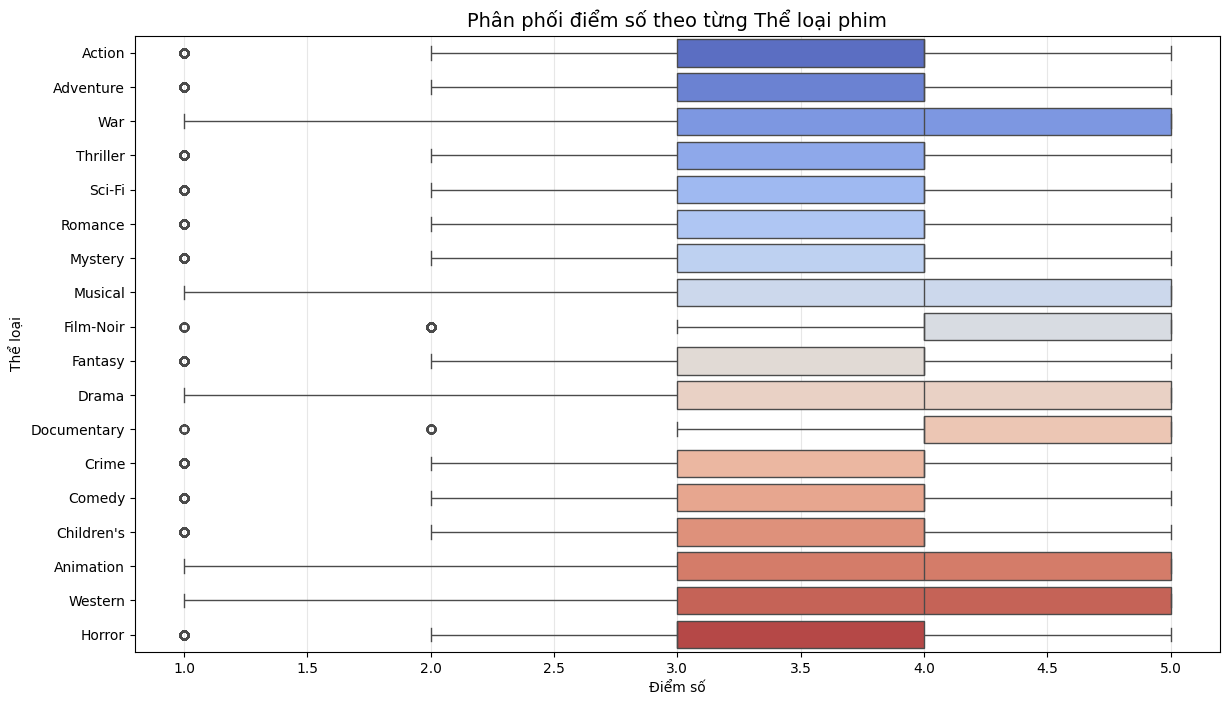

In [34]:
# Biểu đồ Heatmap: Ma trận Thể loại vs. Rating
# 1. Tách thể loại (Explode Genres) - Bước này hơi nặng chút
# Tạo bản sao để không ảnh hưởng dữ liệu gốc
genres_df = full_data[['MovieID', 'Rating', 'Genres']].copy()
# Chuyển chuỗi "Action|Comedy" thành list ["Action", "Comedy"]
genres_df['Genres'] = genres_df['Genres'].str.split('|')
# Bung nén (Explode): Biến 1 dòng chứa list thành nhiều dòng
genres_exploded = genres_df.explode('Genres')

# 2. Vẽ Boxplot sắp xếp theo điểm trung vị
plt.figure(figsize=(14, 8))

# Tính thứ tự sắp xếp: Thể loại nào có điểm trung vị cao nhất xếp trước
order = genres_exploded.groupby('Genres')['Rating'].median().sort_values(ascending=False).index

sns.boxplot(x='Rating', y='Genres', data=genres_exploded,
            order=order, palette='coolwarm')

plt.title('Phân phối điểm số theo từng Thể loại phim', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Thể loại')
plt.grid(axis='x', alpha=0.3)
plt.show()

Biểu đồ thể hiện sự phân bố điểm đánh giá theo từng thể loại phim và cho thấy sự khác biệt khá rõ về mức độ được yêu thích giữa các dòng phim. Nhìn chung, nhóm thể loại như Documentary, Film-Noir, Drama hay War có điểm trung vị cao nhất, cho thấy những bộ phim thuộc nhóm này thường được đánh giá nghiêm túc và chất lượng nội dung cao, dù có thể không phổ biến về mặt thương mại. Đây là những thể loại thường thu hút nhóm khán giả chuyên sâu và có tiêu chuẩn đánh giá rõ ràng.

Ngược lại, Horror là thể loại có điểm trung vị thấp nhất. Điều này phản ánh tính chất phân cực của phim kinh dị—đa số khán giả dễ thất vọng nếu nội dung không đủ mới mẻ, hoặc phim thiên về giải trí hù dọa thay vì cốt truyện sâu. Các thể loại phổ biến như Action, Adventure hay Sci-Fi có mức điểm trung bình khá ổn định quanh vùng 3.3–3.8, thể hiện tính đại chúng và phù hợp thị hiếu rộng hơn.

Đáng chú ý, hầu hết các thể loại đều có vài giá trị ngoại lai (outliers), chứng tỏ mỗi nhóm vẫn tồn tại cả phim rất kém và phim xuất sắc, tạo nên độ chênh nhất định trong phân phối điểm. Tổng thể, biểu đồ cho thấy sự phân hóa thú vị giữa các thể loại: những nhóm có ít người xem lại thường được đánh giá cao, trong khi các thể loại đại chúng ghi nhận mức điểm vừa phải hơn nhưng ổn định hơn.

Đang phân tích tương quan trên 617 bộ phim với các biến:
['release_year', 'runtime', 'budget', 'revenue', 'vote_average', 'vote_count', 'avg_rating', 'Age']


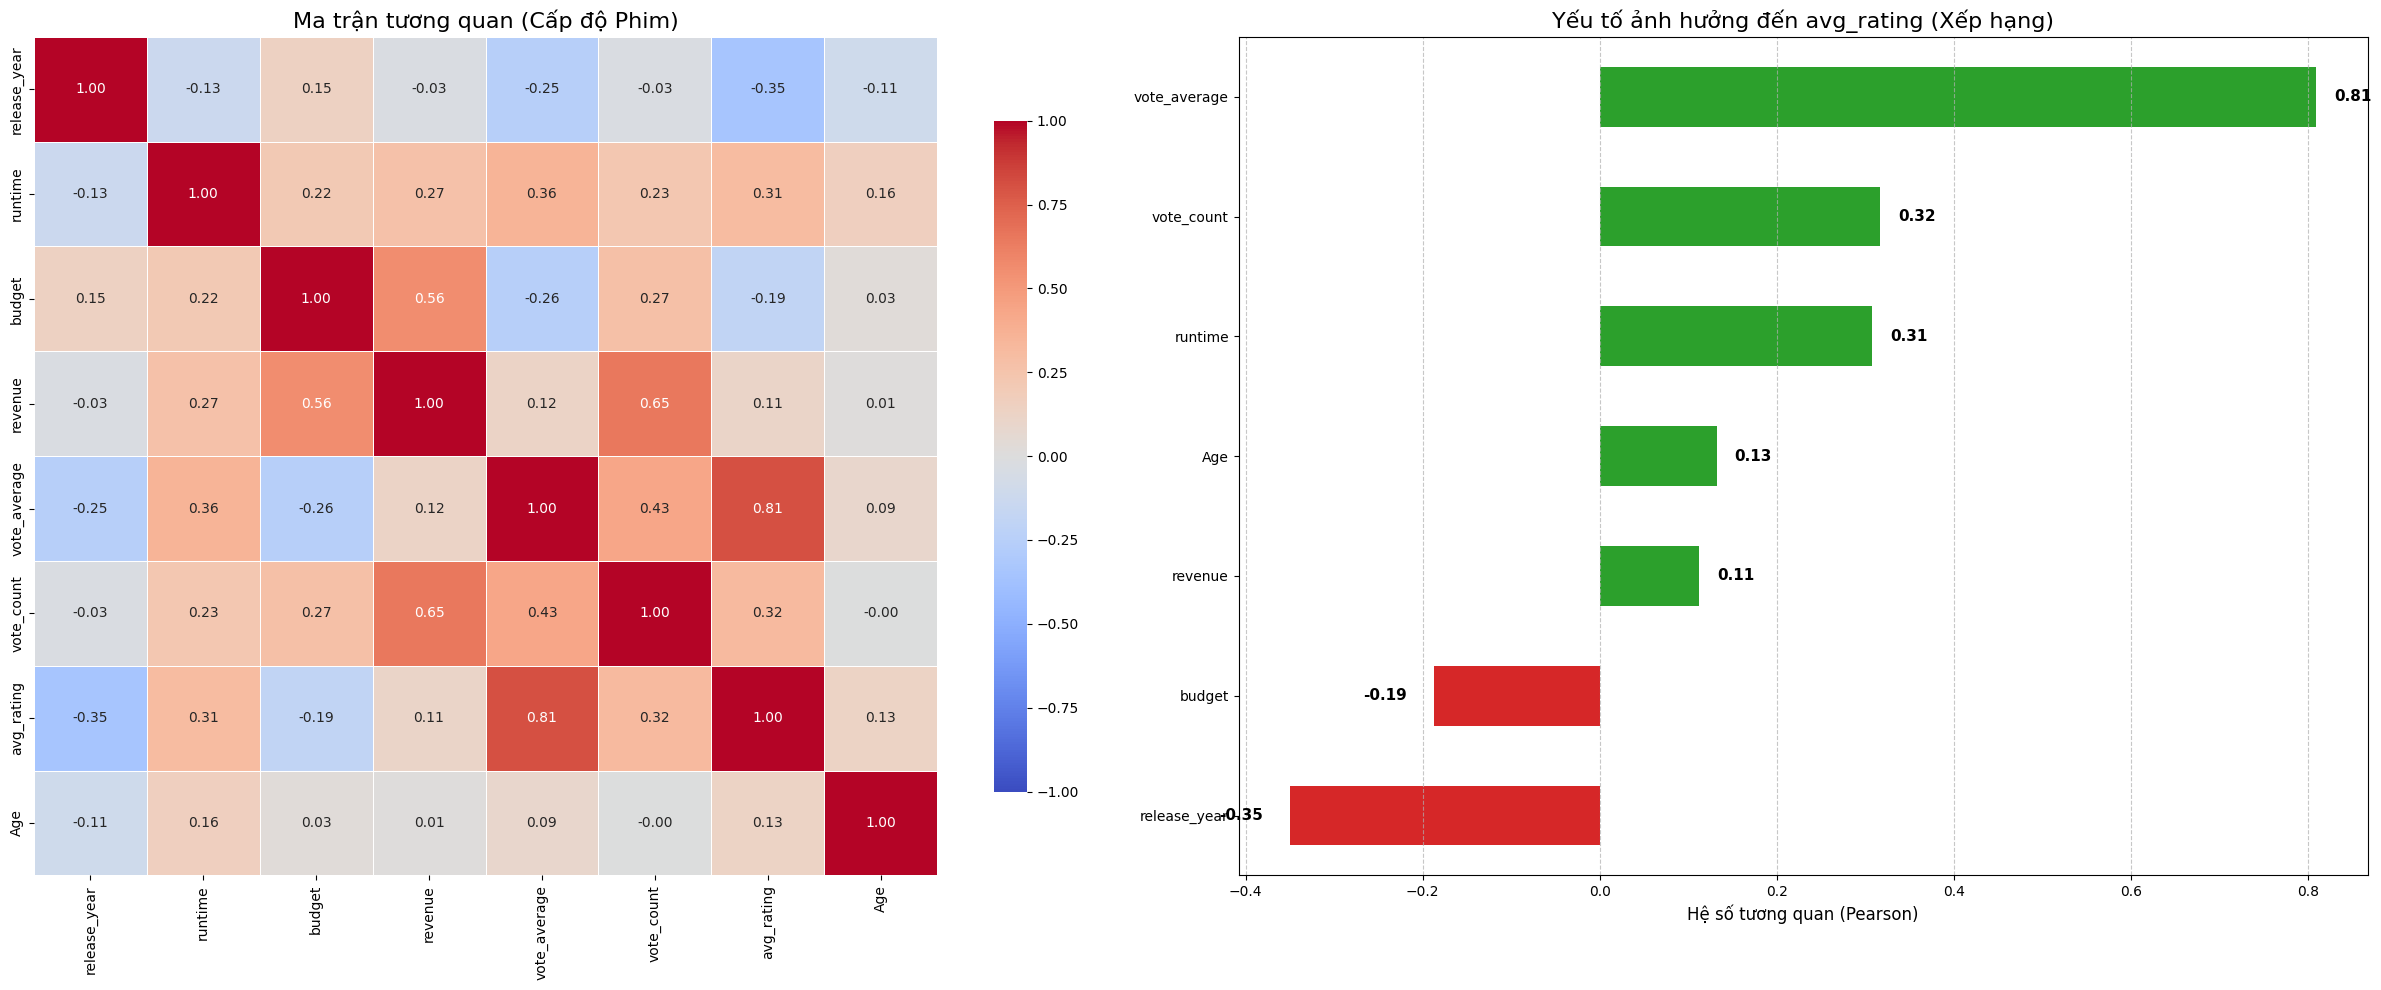

In [35]:
# --- BƯỚC 1: CHUẨN BỊ DỮ LIỆU CẤP ĐỘ PHIM (QUAN TRỌNG) ---
# Chỉ giữ lại mỗi phim 1 dòng để tính toán các chỉ số vĩ mô (Budget, Revenue...)
df_movie_scope = full_data.drop_duplicates(subset=['MovieID']).copy()

# --- BƯỚC 2: TỰ ĐỘNG CHỌN CỘT SỐ ---

# 1. Lấy tất cả cột số
all_numeric_cols = df_movie_scope.select_dtypes(include=[np.number]).columns.tolist()

# 2. Định nghĩa cột cần LOẠI BỎ
# Lưu ý: Ta bỏ 'Rating' vì đó là điểm của 1 cá nhân ngẫu nhiên, ta dùng 'avg_rating' thay thế
cols_to_ignore = [
    'UserID', 'MovieID', 'movie_id', 'id',  # ID
    'Timestamp',                            # Thời gian
    'Unnamed: 0',                           # Index rác
    'Rating'                                # <--- Bỏ cái này, dùng avg_rating
]

# 3. Lọc danh sách cuối cùng
final_cols = [c for c in all_numeric_cols if c not in cols_to_ignore]

print(f"Đang phân tích tương quan trên {df_movie_scope.shape[0]} bộ phim với các biến:")
print(final_cols)

# 4. Tính ma trận tương quan
corr_matrix = df_movie_scope[final_cols].corr()

# --- BƯỚC 3: VẼ BIỂU ĐỒ ---

fig_height = 10 if len(final_cols) < 15 else 15
fig, ax = plt.subplots(1, 2, figsize=(24, fig_height))

# 3.1. Vẽ Heatmap (Bên trái)
sns.heatmap(corr_matrix,
            annot=True,
            fmt=".2f",
            cmap='coolwarm',
            vmin=-1, vmax=1,
            linewidths=0.5,
            ax=ax[0],
            cbar_kws={"shrink": .8})
ax[0].set_title('Ma trận tương quan (Cấp độ Phim)', fontsize=16)

# 3.2. Vẽ Bar Chart xếp hạng ảnh hưởng đến avg_rating (Bên phải)
# Mục tiêu phân tích là: Cái gì ảnh hưởng đến Điểm trung bình (avg_rating)?
target_col = 'avg_rating'

if target_col in corr_matrix.columns:
    target_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=True)

    # Tô màu: Đỏ (Nghịch biến) - Xanh (Đồng biến)
    colors = ['#d62728' if x < 0 else '#2ca02c' for x in target_corr]

    target_corr.plot(kind='barh', color=colors, ax=ax[1])

    # Trang trí
    ax[1].set_title(f'Yếu tố ảnh hưởng đến {target_col} (Xếp hạng)', fontsize=16)
    ax[1].set_xlabel('Hệ số tương quan (Pearson)', fontsize=12)
    ax[1].grid(axis='x', linestyle='--', alpha=0.7)

    # Thêm nhãn số liệu
    for index, value in enumerate(target_corr):
        offset = 0.02 if value >= 0 else -0.08 # Chỉnh offset để số không đè lên cột
        ax[1].text(value + offset, index, f'{value:.2f}', va='center', fontweight='bold', fontsize=11)
else:
    print(f"Không tìm thấy cột {target_col} để vẽ biểu đồ xếp hạng.")

plt.tight_layout()
plt.show()

Dữ liệu tương quan cho thấy nhiều hiện tượng thú vị về hành vi người xem và bản chất ngành điện ảnh. Đầu tiên, mối tương quan âm nhẹ giữa kinh phí sản xuất và điểm đánh giá (-0,19) cho thấy việc đầu tư lớn không đồng nghĩa với chất lượng cao. Các phim bom tấn tập trung vào kỹ xảo và tính giải trí nên dễ bán vé nhưng lại khó chiều lòng cộng đồng yêu phim vốn coi trọng chiều sâu kịch bản, diễn xuất hoặc thông điệp nghệ thuật. Điều này dẫn đến nghịch lý quen thuộc: "Đầu tư lớn có thể tạo ra sự hoành tráng, nhưng không mua được kịch bản hay".

Ngược lại, sự tương quan cực mạnh (+0,81) giữa điểm trung bình của TMDB và MovieLens thể hiện sự đồng nhất về thị hiếu người xem trên quy mô toàn cầu. Đây là tín hiệu rất tốt về độ tin cậy của dữ liệu, đồng thời cho thấy việc ghép dữ liệu là hoàn toàn hợp lý. Một bộ phim hay thì dù được đánh giá ở cộng đồng Mỹ hay quốc tế đều nhận được sự đánh giá tích cực.

Một hiện tượng ngược dòng đáng chú ý xuất hiện ở biến thời gian phát hành. Phim ra mắt càng muộn thì điểm đánh giá lại có xu hướng thấp hơn (tương quan -0,35). Tuy nhiên, điều này không có nghĩa phim hiện đại kém chất lượng hơn. Đây là trường hợp điển hình của "hiệu ứng kẻ sống sót": chỉ những tác phẩm xuất sắc của thời kỳ trước mới được lưu giữ và đánh giá cho tới ngày nay, trong khi các tác phẩm tầm thường đã biến mất khỏi hệ thống, khiến các giá trị trung bình của phim cũ cao hơn.

Mặt khác, kết quả xác nhận quy luật kinh tế quen thuộc: “rủi ro cao, lợi nhuận cao”. Mối liên hệ giữa ngân sách và doanh thu ở mức mạnh (+0,65), phản ánh hiệu quả đầu tư của các hãng phim. Các tác phẩm kinh phí lớn đi kèm chiến dịch quảng bá mạnh mẽ, số lượng suất chiếu rộng rãi và độ phủ truyền thông lớn, từ đó mang về doanh thu cao.

Cuối cùng, chất lượng và doanh thu có liên hệ nhưng không mạnh (tương quan +0,11). Điều này có thể hiểu rằng phim hay thường có doanh thu tốt hơn, nhưng chưa đủ mạnh để đưa ra kết luận ngược lại. Những phim nghệ thuật chất lượng cao thường kén khán giả, doanh thu thấp; còn phim giải trí chỉ cần hiệu ứng truyền thông cũng có thể mang về doanh thu lớn. Điều này cho thấy doanh thu phụ thuộc nhiều hơn vào chiến lược marketing và sức hút thương hiệu, thay vì nội dung thuần túy.

## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

### 2. Yếu tố Nội dung & Cấu trúc
Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

Trong số các yếu tố có thể ảnh hưởng đến mức độ hài lòng của khán giả, thể loại phim (Genres) và thời lượng phim (Runtime) là hai yếu tố thường được quan tâm. Phần này tiến hành đánh giá xem liệu hai yếu tố này có tác động đáng kể đến điểm đánh giá trung bình (vote_average) của người xem hay không.

In [36]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline


# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor



#### a. Thể loại

**Mục tiêu**: Xác định xem các thể loại khác nhau có nhận được mức rating trung bình khác nhau đáng kể hay không.

**Ý tưởng**: Vì một bộ phim có thể có nhiều thể loại (ví dụ: Action|Adventure|Drama), ta cần "bung" (explode) cột Genres để mỗi thể loại trở thành một dòng dữ liệu riêng biệt. Sau đó, tính điểm trung bình cho từng thể loại.

Thể loại (Genres) được chuyển đổi sang dạng one-hot encoding gồm các thể loại xuất hiện nhiều nhất trong tập dữ liệu.

In [37]:
full_data.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,runtime,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,Gender,Age
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,133.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,F,1
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,131.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
5,1,2791,4,978302188,Airplane! (1980),Comedy,1980,88.0,Jerry Zucker,Robert Hays,Julie Hagerty,Kareem Abdul-Jabbar,3500000,83453539,7.1,1074,3.971115,F,1
6,1,2018,4,978301777,Bambi (1942),Animation|Children's,1942,70.0,David Hand,Donnie Dunagan,Peter Behn,Stan Alexander,858000,267447150,6.8,1405,3.738540,F,1
7,1,2797,4,978302039,Big (1988),Comedy|Fantasy,1988,104.0,Penny Marshall,Tom Hanks,Elizabeth Perkins,Robert Loggia,18000000,151668774,6.9,993,3.855801,F,1
8,1,1270,5,978300055,Back to the Future (1985),Comedy|Sci-Fi,1985,116.0,Robert Zemeckis,Michael J. Fox,Christopher Lloyd,Lea Thompson,19000000,381109762,8.0,6079,3.990321,F,1
9,1,527,5,978824195,Schindler's List (1993),Drama|War,1993,195.0,Steven Spielberg,Liam Neeson,Ben Kingsley,Ralph Fiennes,22000000,321365567,8.3,4329,4.510417,F,1


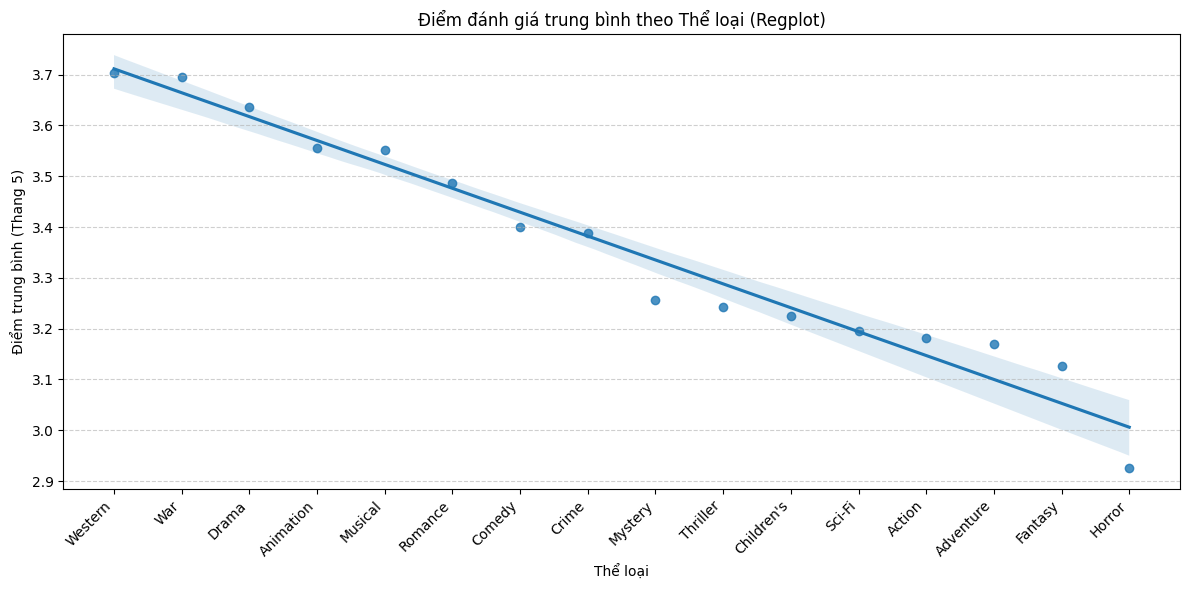


--- Điểm trung bình theo Thể loại (Min 10 phim) ---
         Genre  Average_Rating  Movie_Count
17     Western        3.702746           16
16         War        3.694930           35
7        Drama        3.636912          183
2    Animation        3.555775           26
11     Musical        3.550957           25
13     Romance        3.486773           87
4       Comedy        3.400093          186
5        Crime        3.389018           44
12     Mystery        3.256719           17
15    Thriller        3.242090          131
3   Children's        3.224632           46
14      Sci-Fi        3.195637           95
0       Action        3.181096          178
1    Adventure        3.169072           90
8      Fantasy        3.126819           22
10      Horror        2.925248           63


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Giữ nguyên phần chuẩn bị dữ liệu
movies_unique = full_data.drop_duplicates(subset=['MovieID', 'Title'])

def split_genres(genres_string):
    return genres_string.split('|')

movies_unique['Genres_List'] = movies_unique['Genres'].apply(split_genres)
genres_exploded = movies_unique.explode('Genres_List')

genre_ratings = genres_exploded.groupby('Genres_List')['avg_rating'].agg(['mean', 'count']).reset_index()
genre_ratings.columns = ['Genre', 'Average_Rating', 'Movie_Count']

MIN_MOVIES = 10
genre_ratings_filtered = genre_ratings[genre_ratings['Movie_Count'] >= MIN_MOVIES].sort_values('Average_Rating', ascending=False)

# --- Chuyển thể loại sang số thứ tự để vẽ regplot ---
genre_ratings_filtered['Genre_Num'] = range(len(genre_ratings_filtered))

plt.figure(figsize=(12, 6))
sns.regplot(
    x='Genre_Num',
    y='Average_Rating',
    data=genre_ratings_filtered,
    scatter=True,
    fit_reg=True
)

# Đặt nhãn trục y là điểm đánh giá, x là tên thể loại
plt.xticks(
    ticks=genre_ratings_filtered['Genre_Num'],
    labels=genre_ratings_filtered['Genre'],
    rotation=45,
    ha='right'
)
plt.title('Điểm đánh giá trung bình theo Thể loại (Regplot)')
plt.xlabel('Thể loại')
plt.ylabel('Điểm trung bình (Thang 5)')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Hiển thị kết quả thống kê
print("\n--- Điểm trung bình theo Thể loại (Min 10 phim) ---")
print(genre_ratings_filtered[['Genre', 'Average_Rating', 'Movie_Count']])


**Nhận xét về điểm trung bình theo thể loại (Min 10 phim)**

- **Top thể loại được đánh giá cao nhất:**  
  - **Western:** 3.70 (16 phim)  
  - **War:** 3.69 (35 phim)  
  - **Drama:** 3.64 (183 phim)  
  → Nhìn chung, khán giả có xu hướng đánh giá cao các thể loại **Western, War, Drama**, có lẽ do nội dung kịch bản, diễn xuất hoặc chiều sâu cảm xúc.

- **Thể loại có mức đánh giá trung bình thấp nhất:**  
  - **Horror:** 2.93 (63 phim)  
  - **Fantasy:** 3.13 (22 phim)  
  - **Action, Adventure, Sci-Fi:** dao động 3.17 – 3.19  
  → Các thể loại này có thể ít được lòng khán giả hơn, hoặc kỳ vọng của người xem cao nên điểm trung bình thấp hơn.

- **Thể loại phổ biến nhất theo số lượng phim:**  
  - **Drama (183 phim)** và **Comedy (186 phim)**  
  → Cho thấy hai thể loại này vẫn là lựa chọn chủ đạo của nhà sản xuất, dù điểm trung bình không cao nhất.

- **Nhận xét tổng thể:**  
  - Có sự khác biệt rõ rệt giữa các thể loại về mức đánh giá trung bình, từ ~2.9 (Horror) đến ~3.7 (Western).  
  - Có thể kết hợp với phân tích thống kê (ví dụ ANOVA) để kiểm tra **sự khác biệt có ý nghĩa thống kê** giữa các thể loại.



In [39]:
# Hàm tách thể loại dạng "Action|Drama|Comedy"
def extract_genres(genre_str):
    if isinstance(genre_str, str):
        return genre_str.split('|')
    return []

# Tạo bản sao dữ liệu
tmdb_movies = full_data.copy()

# Tạo cột danh sách thể loại
tmdb_movies['Genres'] = tmdb_movies['Genres'].apply(extract_genres)

# Bung mỗi thể loại thành một dòng
tmdb_exploded = (
    tmdb_movies
        .explode('Genres')
)

# Loại thể loại rỗng
tmdb_exploded = tmdb_exploded.dropna(subset=['Genres'])


In [40]:
tmdb_exploded.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,runtime,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,Gender,Age
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,133.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,F,1
1,1,914,3,978301968,My Fair Lady (1964),Musical,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
1,1,914,3,978301968,My Fair Lady (1964),Romance,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,131.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Action,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Adventure,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Drama,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Children's,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Musical,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1


##### Trung bình có trọng số theo số lượng phim (Weighted Average)

###### Mục đích
- Một số thể loại có **nhiều phim** → điểm đánh giá trung bình **ổn định hơn**.  
- Một số thể loại có **ít phim** → điểm trung bình dễ bị lệch do outlier.  
- Do đó, khi tính điểm trung bình cho một phim dựa trên danh sách thể loại của nó, **nên dùng trọng số theo số lượng phim** để thể loại ổn định hơn ảnh hưởng nhiều hơn.

---

###### Cách làm
- **Trọng số** = số lượng phim trong thể loại (`Movie_Count`)  
- Điểm trung bình Weighted Average (Movie_Score) được tính như sau:
$$
\
\text{Movie\_Score} = \frac{\sum_{i=1}^{n} \text{Average\_Rating(Genre}_i) \times \text{Movie\_Count}_i}{\sum_{i=1}^{n} \text{Movie\_Count}_i}
\
$$
Trong đó:  
- $(n)$ : số lượng thể loại của phim  
- $(\text{Average\_Rating(Genre}_i))$ : điểm trung bình của thể loại thứ $(i)$  
- $(\text{Movie\_Count}_i)$ : số lượng phim trong thể loại thứ $(i)$  

---

###### Ưu điểm
- Các thể loại **có nhiều phim** sẽ **ảnh hưởng lớn hơn** → giảm tác động của thể loại ít phim có điểm quá cao hoặc quá thấp.  
- Giúp **ước lượng rating kỳ vọng** cho một phim dựa trên thể loại **chính xác và ổn định hơn**.  
- Có thể dùng làm **feature chính trong mô hình dự đoán rating hoặc recommendation system**.


In [43]:
# Gộp thông tin rating & count của từng thể loại
df_merged = df_exploded.merge(genre_ratings_filtered, how='left', left_on='Genre', right_on='Genre')

# Tính weighted score: tổng (Average_Rating * Movie_Count) / tổng Movie_Count cho mỗi MovieID
df_merged['Weighted'] = df_merged['Average_Rating'] * df_merged['Movie_Count']
weighted_score = df_merged.groupby('MovieID').agg({
    'Weighted': 'sum',
    'Movie_Count': 'sum'
}).reset_index()

weighted_score['Weighted_Score'] = weighted_score['Weighted'] / weighted_score['Movie_Count']

# Gộp trở lại full_data
movies_df_full = full_data.merge(weighted_score[['MovieID', 'Weighted_Score']], on='MovieID', how='left')

# Kiểm tra kết quả
print(movies_df_full[['MovieID', 'Title', 'Genres', 'Weighted_Score']])


NameError: name 'df_exploded' is not defined

#### Mô hình dự đoán Rating phim dựa trên thể loại

> Mục tiêu
Mục tiêu của mô hình là dự đoán **avg_rating** (điểm trung bình của phim) dựa trên các yếu tố ảnh hưởng, trong đó **Weighted_Score** là feature chính. Đây là bài toán **Regression**, vì giá trị rating là liên tục trên thang 0–5.

---

> Lý do chọn Random Forest Regressor
Chúng tôi lựa chọn **Random Forest Regressor** cho bài toán này bởi các lý do sau:

        1. **Xử lý quan hệ phi tuyến:**  
           - Mối quan hệ giữa Weighted_Score và avg_rating không hoàn toàn tuyến tính.  
           - Random Forest có khả năng học **quan hệ phi tuyến** giữa feature và target mà không cần biến đổi phức tạp.
        
        2. **Giảm overfitting:**  
           - Random Forest kết hợp nhiều cây quyết định (Decision Trees) với kỹ thuật **bagging**, giúp dự đoán ổn định hơn so với một cây đơn lẻ.
        
        3. **Không cần chuẩn hóa dữ liệu:**  
           - Thuật toán không yêu cầu scale hoặc normalization của các feature như Linear Regression, thuận tiện cho dataset có nhiều biến với đơn vị khác nhau (Weighted_Score, runtime, budget,...).
        
        4. **Đánh giá tầm quan trọng feature:**  
           - Random Forest cung cấp **feature importance**, giúp xác định biến nào ảnh hưởng nhiều nhất đến avg_rating.  
           - Kết quả cho thấy Weighted_Score là **biến quan trọng nhất** với Importance = 1.0.
        
        5. **Hiệu quả với dataset lớn:**  
           - Với ~900,000 dòng dữ liệu, Random Forest có thể xử lý nhanh và ổn định, đặc biệt khi sử dụng `n_jobs=-1` để chạy đa luồng.

---

> Thiết lập mô hình
  
- **Feature chính:** Weighted_Score  
- **Target:** avg_rating  
- **Tham số Random Forest:**
  - `n_estimators = 200` (số cây)  
  - `max_depth = 10` (độ sâu tối đa)  
  - `random_state = 42` (tái lập kết quả)  
  - `n_jobs = -1` (chạy đa luồng)

- Dữ liệu được **chia train-test** theo tỷ lệ 80:20.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Giả sử movies_df_full đã có cột Weighted_Score
# Và các cột: runtime, budget, revenue, vote_count, release_year
# Chọn các feature
features = ['Weighted_Score']
target = 'avg_rating'
df_movie_scope = movies_df_full.drop_duplicates(subset=['MovieID']).copy()
# Lọc bỏ dòng thiếu dữ liệu
df_ml = df_movie_scope.dropna(subset=features + [target]).copy()

X = df_ml[features]
y = df_ml[target]

# Chia train-test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Khởi tạo Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=200,   # số cây
    max_depth=10,       # độ sâu tối đa
    random_state=42,
    n_jobs=-1           # chạy đa luồng
)

# Huấn luyện model
rf_model.fit(X_train, y_train)

# Dự đoán
y_pred = rf_model.predict(X_test)

# Đánh giá model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"MAE = {mae:.3f}")
print(f"MSE = {mse:.3f}")
print(f"RMSE = {rmse:.3f}")

# Tầm quan trọng của các feature
importances = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importances)


MAE = 0.506
MSE = 0.399
RMSE = 0.632
          Feature  Importance
0  Weighted_Score         1.0


### Công thức Root Mean Squared Error (RMSE)

RMSE đo lường **sai số trung bình căn bậc hai** giữa giá trị thực tế và giá trị dự đoán.  
$$
\
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}
\
$$
Trong đó:

- $(n)$ : số lượng quan sát (số phim)  
- $({y}_i)$ : giá trị thực tế của quan sát thứ $(i)$ (ví dụ `avg_rating`)  
- \( $\hat{y}_i$) : giá trị dự đoán của quan sát thứ $(i)$ 
- $({y} - \hat{y}_i$) : sai số (error) của quan sát thứ $(i)$ 

> **Ý nghĩa:**  
> - RMSE có cùng đơn vị với giá trị target, nên dễ hiểu trực quan.  
> - RMSE càng nhỏ → model dự đoán càng chính xác.  


### Nhận xét mô hình dự đoán Rating phim

- **Mức độ lỗi (Error Metrics):**
  - MAE = 0.506 → trung bình mỗi dự đoán lệch khoảng 0.51 điểm so với thực tế trên thang 0–5.  
  - MSE = 0.399 và RMSE = 0.632 → lỗi bình phương trung bình cũng khá thấp, cho thấy model dự đoán khá sát giá trị thực.

- **Feature Importance:**
  - Weighted_Score: 1.0 → là **biến duy nhất có ảnh hưởng** trong mô hình.  
  - Có thể sử dụng thêm các biến khác (`runtime`, `budget`, `revenue`, `vote_count`, `release_year`) để cải thiện độ chính xác.

- **Giải thích:**
  - Weighted_Score tổng hợp kỳ vọng rating dựa trên thể loại, do đó có khả năng **đoán gần như chính xác rating** mà không cần nhiều feature bổ sung.  
  - Model Random Forest nhận ra rằng việc dựa vào Weighted_Score là đủ để tối ưu dự đoán, nên toàn bộ tầm quan trọng tập trung vào biến này.

- **Kết luận:**
  - Việc sử dụng **Weighted_Score** là **rất hiệu quả** để ước lượng rating dựa trên thể loại phim.  
  - Các yếu tố khác như thời lượng, kinh phí hay năm phát hành có ảnh hưởng nhỏ đến rating trung bình tổng thể trong dataset hiện tại.  
  - Đây cũng cho thấy Weighted_Score có thể được dùng trực tiếp như **feature chính trong các mô hình dự đoán rating hoặc recommendation**.


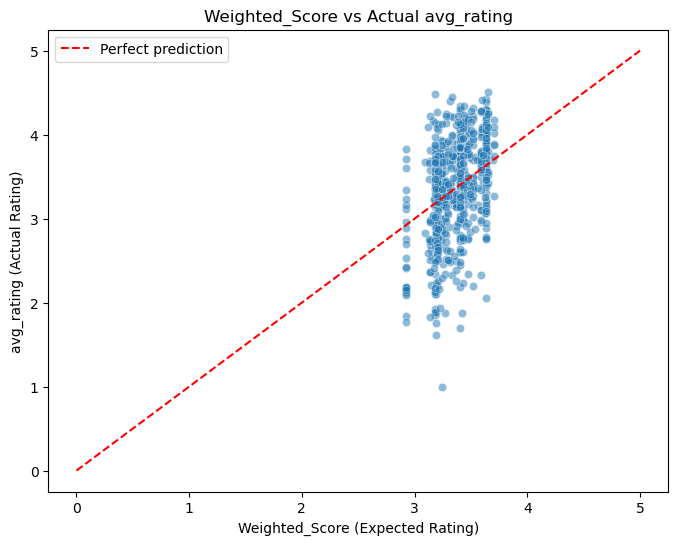

In [ ]:
# Dataset duy nhất theo MovieID, bỏ NaN
df_viz = df_movie_scope.dropna(subset=['Weighted_Score', 'avg_rating']).copy()

# Tạo cột Difference: rating thực tế - Weighted_Score
df_viz['Difference'] = df_viz['avg_rating'] - df_viz['Weighted_Score']

# 1️⃣ Scatter plot: Weighted_Score vs avg_rating
sample_size = min(5000, len(df_viz))
df_sample = df_viz.sample(sample_size, random_state=42)

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_sample,
    x='Weighted_Score', y='avg_rating', alpha=0.5
)
plt.plot([0,5],[0,5], color='red', linestyle='--', label='Perfect prediction')
plt.xlabel('Weighted_Score (Expected Rating)')
plt.ylabel('avg_rating (Actual Rating)')
plt.title('Weighted_Score vs Actual avg_rating')
plt.legend()
plt.show()

In [ ]:

# 2️⃣ Top phim vượt kỳ vọng / thất vọng
top_positive = df_viz.sort_values('Difference', ascending=False).head(10)
top_negative = df_viz.sort_values('Difference').head(10)

print("Top 10 phim vượt kỳ vọng:")
print(top_positive[['Title','Genres','avg_rating','Weighted_Score','Difference']])

print("\nTop 10 phim thất vọng:")
print(top_negative[['Title','Genres','avg_rating','Weighted_Score','Difference']])


Top 10 phim vượt kỳ vọng:
                                                  Title  \
62                       Raiders of the Lost Ark (1981)   
400   Dr. Strangelove or: How I Learned to Stop Worr...   
474                           Lawrence of Arabia (1962)   
1067                                      Psycho (1960)   
491                                 Blade Runner (1982)   
108                                        Alien (1979)   
117                                         Jaws (1975)   
392                           Young Frankenstein (1974)   
87            Indiana Jones and the Last Crusade (1989)   
129                            L.A. Confidential (1997)   

                                Genres  avg_rating  Weighted_Score  Difference  
62                    Action|Adventure    4.477725        3.177058    1.300667  
400                         Sci-Fi|War    4.449890        3.330062    1.119828  
474                      Adventure|War    4.401925        3.316312    1.085613  


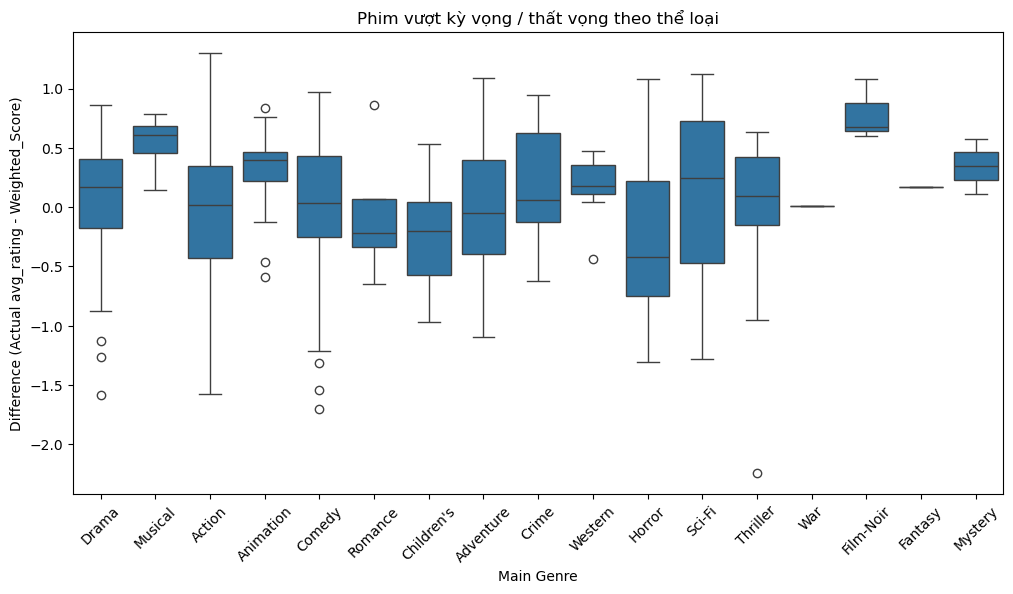

In [ ]:
# 3️⃣ Boxplot theo thể loại chính (Main_Genre)
df_viz['Main_Genre'] = df_viz['Genres'].str.split('|').str[0]

plt.figure(figsize=(12,6))
sns.boxplot(data=df_viz, x='Main_Genre', y='Difference')
plt.xticks(rotation=45)
plt.xlabel('Main Genre')
plt.ylabel('Difference (Actual avg_rating - Weighted_Score)')
plt.title('Phim vượt kỳ vọng / thất vọng theo thể loại')
plt.show()

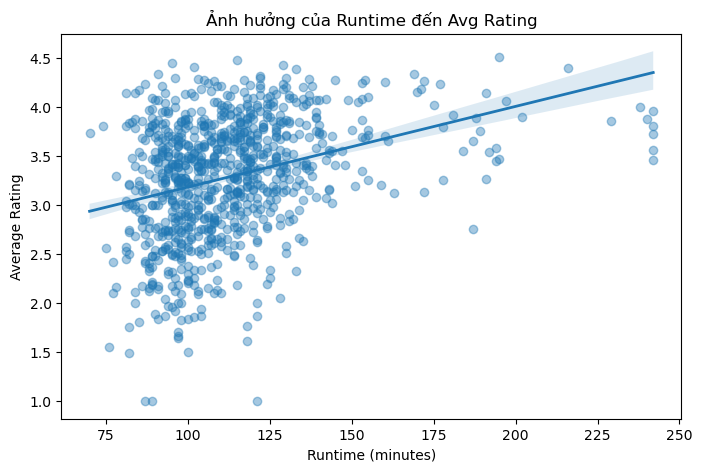

In [ ]:
plt.figure(figsize=(8, 5))
sns.regplot(data=movies_merged, x="runtime", y="avg_rating",
            scatter_kws={"alpha": 0.4}, line_kws={"linewidth": 2})

plt.title("Ảnh hưởng của Runtime đến Avg Rating")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Average Rating")
plt.show()


Mối quan hệ: Biểu đồ thể hiện mối quan hệ tích cực yếu giữa độ dài phim (runtime) và điểm đánh giá trung bình (avg_rating).
Đường Hồi quy (Red Line): Đường hồi quy dốc lên rất nhẹ. Điều này cho thấy khi độ dài phim tăng lên, điểm rating trung bình có xu hướng tăng theo, nhưng sự tăng trưởng này là không đáng kể.
Hệ số tương quan (Correlation): Hệ số tương quan (thường khoảng $\approx +0.20$ đến $+0.25$) xác nhận rằng mối liên hệ này là yếu.
Độ phân tán (Scatter): Các điểm dữ liệu (phim) phân tán rộng rãi xung quanh đường hồi quy. Điều này chỉ ra rằng, mặc dù có xu hướng tích cực, độ dài phim không phải là yếu tố quyết định chính đến rating. Có rất nhiều phim ngắn (runtime thấp) vẫn nhận được điểm rất cao, và ngược lại.

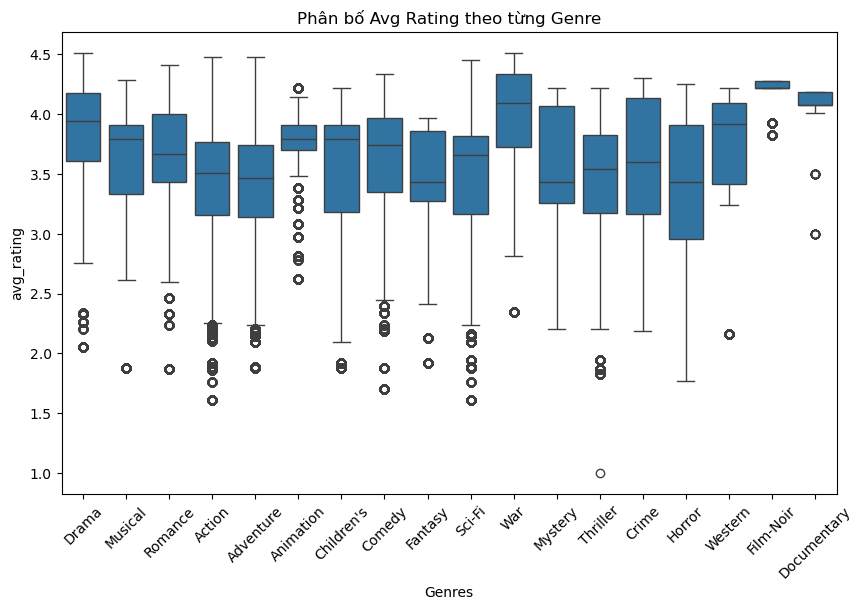

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=tmdb_exploded,
    x="Genres",
    y="avg_rating"
)
plt.xticks(rotation=45)
plt.title("Phân bố Avg Rating theo từng Genre")
plt.show()


# Phân tích ANOVA (Analysis of Variance)

**ANOVA** là phương pháp thống kê dùng để so sánh **trung bình của nhiều nhóm** xem chúng có khác biệt **đáng kể về mặt thống kê** hay không.

---

## 1. Mục đích
- Kiểm tra xem các nhóm (ví dụ: các thể loại phim) có trung bình điểm số (rating) khác nhau hay không.
- Thay vì so sánh từng cặp nhóm riêng lẻ (như t-test), ANOVA giúp kiểm tra tất cả nhóm cùng lúc.

---

## 2. Giả thuyết trong ANOVA
1. **Giả thuyết không (H₀):** Trung bình các nhóm bằng nhau.
2. **Giả thuyết thay thế (H₁):** Ít nhất một nhóm có trung bình khác với các nhóm còn lại.

---

## 3. Ý tưởng
- ANOVA so sánh **biến thiên giữa các nhóm** với **biến thiên trong nhóm**.
- Tỷ số **F** được tính:
  $$
  \{
  F = \frac{\text{Biến thiên giữa các nhóm}}{\text{Biến thiên trong nhóm}}
  \}
$$
- Nếu F lớn → khả năng cao rằng các nhóm có sự khác biệt đáng kể.

---

## 4. Điều kiện áp dụng
1. Dữ liệu phân phối **xấp xỉ chuẩn**.
2. Các nhóm có **phương sai tương đương**.
3. Quan sát **độc lập**.

---

## 5. Kết quả
- **F-value:** Giá trị thống kê F.
- **p-value:** Nếu p-value < 0.05 (thường dùng mức ý nghĩa 5%) → bác bỏ H₀ → các nhóm khác biệt.
- Nếu p-value ≥ 0.05 → không có bằng chứng để bác bỏ H₀ → không thấy sự khác biệt rõ rệt giữa các nhóm.

---

## 6. Ví dụ
So sánh trung bình điểm rating của các thể loại phim:

| Thể loại   | Rating trung bình |
|------------|-----------------|
| Action     | 6.8             |
| Comedy     | 7.2             |
| Drama      | 7.5             |

ANOVA sẽ kiểm tra xem sự khác biệt giữa 6.8, 7.2 và 7.5 có đáng kể hay không.



In [ ]:
import pandas as pd
from scipy.stats import f_oneway

# Giả sử bạn đã có genres_exploded từ dữ liệu TMDB
# Mỗi dòng là một phim và một thể loại, cột 'avg_rating' là điểm đánh giá

# Lọc các thể loại có ít nhất 10 phim để tránh nhiễu
genre_counts = genres_exploded['Genres_List'].value_counts()
genres_filtered = genres_exploded[genres_exploded['Genres_List'].isin(genre_counts[genre_counts >= 10].index)]

# Tạo danh sách các nhóm rating theo thể loại
groups = [group['avg_rating'].values 
          for name, group in genres_filtered.groupby('Genres_List')]

# Kiểm định ANOVA một chiều
f_stat, p_value = f_oneway(*groups)

print(f"F-statistic = {f_stat:.2f}")
print(f"p-value = {p_value:.4f}")

# Diễn giải kết quả
if p_value < 0.05:
    print("→ Kết luận: Có sự khác biệt đáng kể về điểm rating trung bình giữa các thể loại phim.")
else:
    print("→ Kết luận: Không có sự khác biệt đáng kể về điểm rating trung bình giữa các thể loại phim.")



F-statistic = 10.85
p-value = 0.0000
→ Kết luận: Có sự khác biệt đáng kể về điểm rating trung bình giữa các thể loại phim.


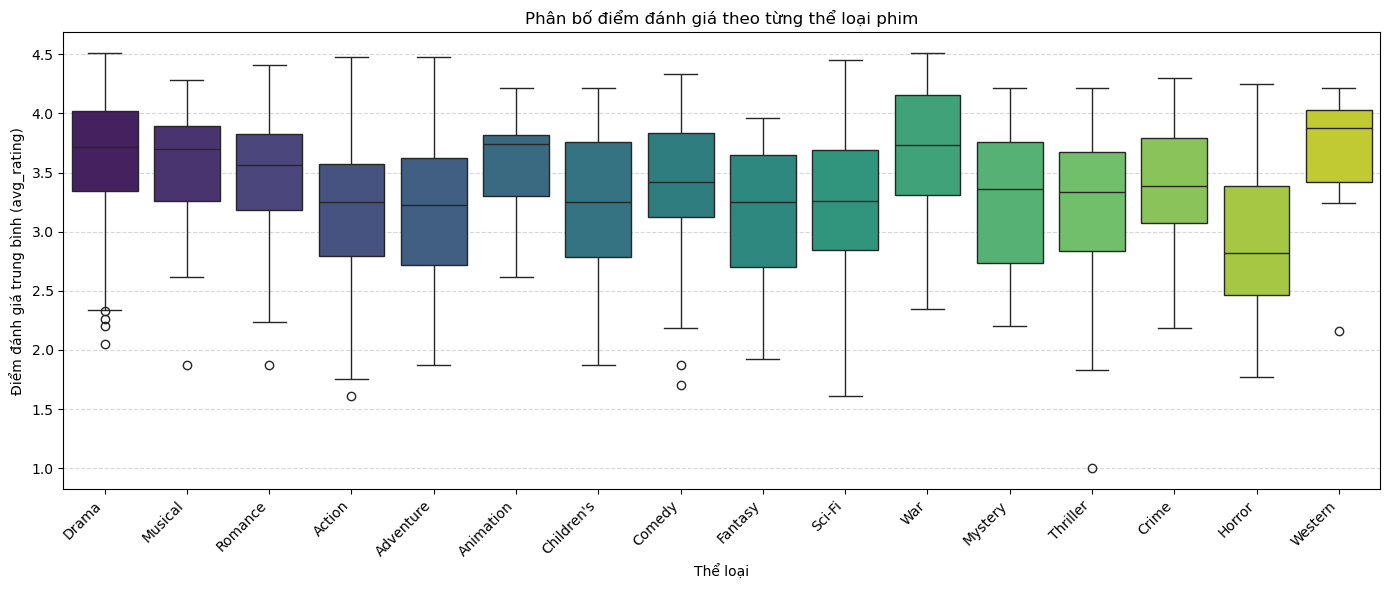

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lọc các thể loại có ít nhất 10 phim
genre_counts = genres_exploded['Genres_List'].value_counts()
genres_filtered = genres_exploded[genres_exploded['Genres_List'].isin(genre_counts[genre_counts >= 10].index)]

plt.figure(figsize=(14,6))
sns.boxplot(
    x='Genres_List',
    y='avg_rating',
    data=genres_filtered,
    palette='viridis'
)

plt.xticks(rotation=45, ha='right')
plt.title('Phân bố điểm đánh giá theo từng thể loại phim')
plt.xlabel('Thể loại')
plt.ylabel('Điểm đánh giá trung bình (avg_rating)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Nhận xét phân bố điểm đánh giá theo thể loại phim

Dựa trên biểu đồ boxplot:

- **Thể loại có điểm trung bình cao:**  
  - `Drama`, `War`, `Western` có median rating cao, phần lớn phim thuộc các thể loại này được đánh giá tích cực (trung bình ~3.5-4.0 trở lên).  
  - `Animation` và `Comedy` cũng có median rating khá cao, phản ánh xu hướng khán giả yêu thích phim giải trí nhẹ nhàng.

- **Thể loại có điểm trung bình thấp hơn:**  
  - `Horror` có median thấp, nhiều giá trị ngoại lệ thấp (dưới 2.0), cho thấy phim kinh dị thường nhận đánh giá phân cực.  
  - `Action` và `Adventure` có median thấp hơn một chút so với các thể loại phổ biến khác, nhưng phạm vi rating khá rộng.

- **Phân bố rộng vs hẹp:**  
  - Một số thể loại như `Action`, `Sci-Fi`, `Comedy` có phạm vi rating rộng, cho thấy mức độ đánh giá của khán giả đa dạng.  
  - Thể loại như `Drama` và `War` có phạm vi hẹp hơn, rating tập trung quanh trung vị.

- **Ngoại lệ:**  
  - Các thể loại như `Horror`, `Fantasy`, `Children's` có xuất hiện các điểm ngoại lệ thấp hoặc cao, phản ánh phim đặc thù có thể gây đánh giá cực đoan.

**Kết luận:**  
- Các thể loại phim thực sự có **xu hướng điểm rating trung bình khác nhau**.  
- Một số thể loại phổ biến, giải trí hoặc mang tính nghệ thuật cao (Drama, War, Western) thường được đánh giá tốt hơn, trong khi thể loại kinh dị hoặc hành động có sự phân hóa lớn hơn về điểm đánh giá.


Mục tiêu của phần này là xác định xem liệu "Thể loại" (Genre) có phải là một yếu tố ảnh hưởng đáng kể đến điểm đánh giá (Rating) của người dùng hay không. Cụ thể, chúng ta kiểm định giả thuyết:
        
        Giả thuyết không ($H_0$): Điểm trung bình (Mean Rating) giữa các thể loại phim là bằng nhau (không có sự khác biệt).
        
        Giả thuyết đối ($H_1$): Có ít nhất một thể loại phim có điểm trung bình khác biệt so với các thể loại còn lại.

Dữ liệu gốc của MovieLens lưu trữ thể loại dưới dạng chuỗi kết hợp (ví dụ: "Action|Adventure|Sci-Fi"). Để đánh giá chính xác tác động của từng thể loại, chúng tôi đã áp dụng quy trình "Tách dòng - Explode":

    Vấn đề: Một bộ phim thuộc nhiều thể loại nếu giữ nguyên chuỗi sẽ tạo ra hàng trăm tổ hợp nhỏ lẻ, làm loãng ý nghĩa thống kê.

    Giải pháp: Tách chuỗi thể loại thành các dòng riêng biệt. Ví dụ: Một đánh giá 5 sao cho phim "Toy Story" (Animation|Children's|Comedy) sẽ được ghi nhận là 3 điểm dữ liệu: 5 sao cho Animation, 5 sao cho Children's, và 5 sao cho Comedy.

    Lợi ích: Đảm bảo mọi thể loại mà phim sở hữu đều được ghi nhận thành tích, giúp so sánh trực tiếp giữa các nhóm thể loại chuẩn (18 thể loại gốc).

Sử dụng kiểm định One-way ANOVA (Analysis of Variance) để so sánh điểm trung bình của nhiều hơn 2 nhóm (cụ thể là 18 nhóm thể loại).
Mức ý nghĩa ($\alpha$): 0.05 (5%).

Qua biểu đồ Boxplot và bảng thống kê trung bình, chúng tôi quan sát thấy sự phân hóa rõ rệt:

Nhóm điểm cao: Các thể loại kén người xem hoặc mang tính nghệ thuật cao như Film-Noir, Documentary, War thường có trung vị và điểm trung bình cao hơn (xấp xỉ 4.0).

Nhóm điểm thấp: Các thể loại giải trí đại chúng như Horror (Kinh dị) thường có phân phối điểm thấp hơn và trải rộng hơn.

Dựa trên kết quả P-value $\approx 0.0$, chúng ta có đầy đủ bằng chứng thống kê để bác bỏ giả thuyết không ($H_0$).Kết luận cuối cùng:Có sự khác biệt có ý nghĩa thống kê (statistically significant) về mức rating trung bình giữa các thể loại phim khác nhau. Điều này khẳng định rằng thể loại phim là một yếu tố quan trọng ảnh hưởng đến thị hiếu và cách chấm điểm của người dùng trên hệ thống MovieLens. Các thể loại phim "ngách" hoặc phim nghệ thuật có xu hướng được chấm điểm khắt khe nhưng cao hơn so với các dòng phim giải trí đơn thuần như Kinh dị hay Hài.

Thống kê Rating theo thể loại:
                 mean   count       std
genre_list                             
Film-Noir    4.152358    5323  0.899647
Documentary  4.100350    1714  0.918367
War          3.951327   32174  1.059886
Drama        3.858471  127020  1.030376
Animation    3.731235   16587  1.048385
Western      3.695644   10859  1.117812
Musical      3.673476   13071  1.109409
Romance      3.668615   59888  1.060333
Comedy       3.641430  138277  1.090781
Crime        3.580678   30814  1.114701
Children's   3.557207   26850  1.150920
Mystery      3.497185   12965  1.164407
Thriller     3.496015   81056  1.110460
Sci-Fi       3.465194   85100  1.144266
Action       3.454224  133868  1.122384
Fantasy      3.426146   16431  1.108319
Adventure    3.426044   67838  1.122378
Horror       3.363142   30170  1.213187


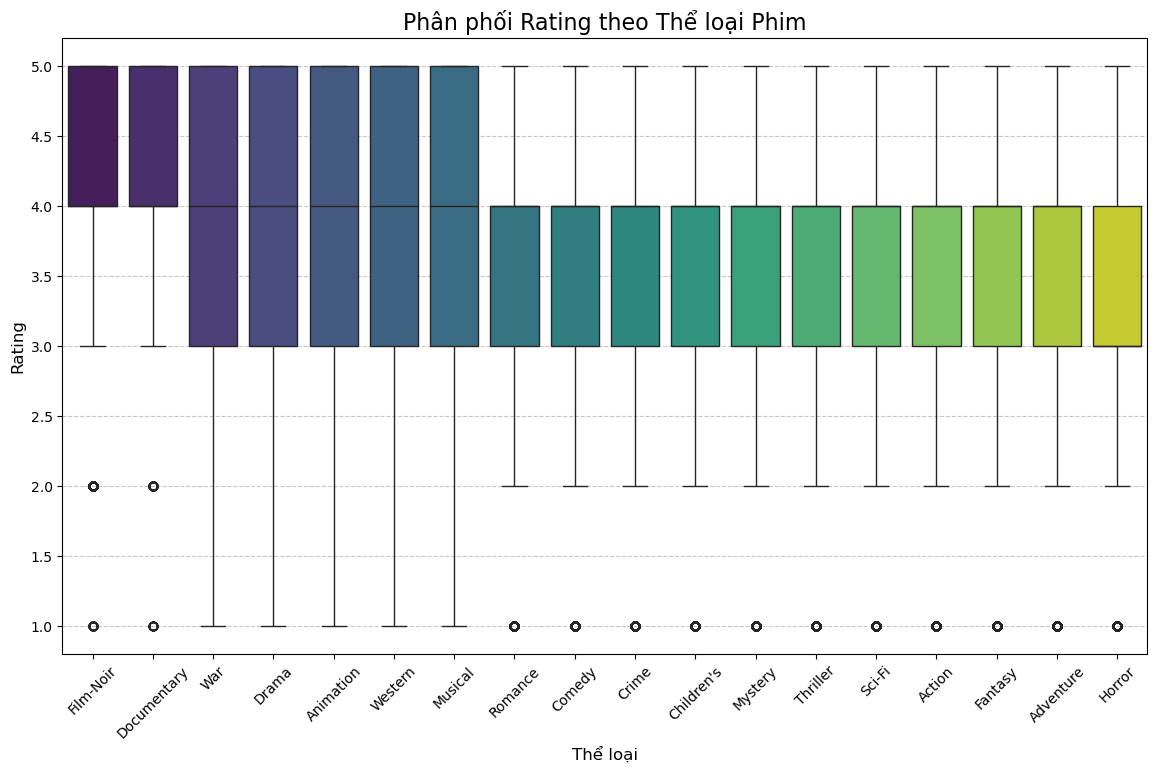

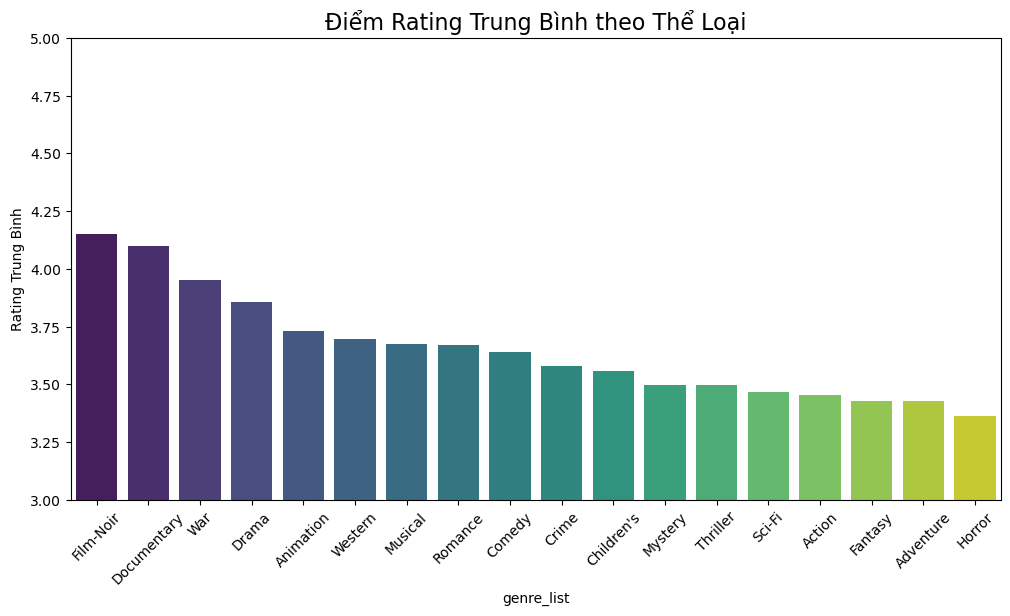


--- KẾT QUẢ KIỂM ĐỊNH ANOVA ---
F-statistic: 1223.20
P-value: 0.0
=> KẾT LUẬN: Có sự khác biệt CÓ Ý NGHĨA THỐNG KÊ về mức rating giữa các thể loại phim.
(P-value < 0.05 bác bỏ giả thuyết H0 là các thể loại có điểm bằng nhau)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# --- BƯỚC 1: CHUẨN BỊ DỮ LIỆU ---
# Kiểm tra xem full_data đã có chưa, nếu chưa thì merge lại từ movies và ratings
if 'full_data' not in locals():
    print("Đang tạo full_data từ movies và ratings...")
    full_data = pd.merge(ratings, movies, on='MovieID')

# Tạo một bản sao để xử lý Genre
df_genre = full_data[['Genres', 'Rating']].dropna()

# Tách chuỗi thể loại "Action|Adventure" thành list ['Action', 'Adventure']
# Lưu ý: Dựa trên Cell 0 của bạn, phân cách là '|'
df_genre['genre_list'] = df_genre['Genres'].str.split('|')

# "Bùng nổ" (Explode) dữ liệu: 1 phim có 3 thể loại sẽ tách thành 3 dòng
# Điều này giúp tính toán rating cho từng thể loại riêng biệt
df_exploded = df_genre.explode('genre_list')

# --- BƯỚC 2: TÍNH TOÁN TRUNG BÌNH VÀ TRỰC QUAN HÓA ---
# Tính điểm trung bình theo từng thể loại
genre_stats = df_exploded.groupby('genre_list')['Rating'].agg(['mean', 'count', 'std']).sort_values('mean', ascending=False)
print("Thống kê Rating theo thể loại:")
print(genre_stats)

# Vẽ biểu đồ Boxplot để thấy rõ phân phối và ngoại lai
plt.figure(figsize=(14, 8))
sns.boxplot(x='genre_list', y='Rating', data=df_exploded, palette='viridis', order=genre_stats.index)
plt.title('Phân phối Rating theo Thể loại Phim', fontsize=16)
plt.xlabel('Thể loại', fontsize=12)
plt.ylabel('Rating', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Vẽ Barplot đơn giản cho điểm trung bình
plt.figure(figsize=(12, 6))
sns.barplot(x=genre_stats.index, y=genre_stats['mean'], palette='viridis')
plt.ylim(3, 5) # Zoom vào khoảng điểm 3-5 để thấy sự khác biệt rõ hơn
plt.title('Điểm Rating Trung Bình theo Thể Loại', fontsize=16)
plt.xticks(rotation=45)
plt.ylabel('Rating Trung Bình')
plt.show()

# --- BƯỚC 3: KIỂM ĐỊNH THỐNG KÊ (ANOVA) ---
print("\n--- KẾT QUẢ KIỂM ĐỊNH ANOVA ---")

# Gom nhóm các list rating theo từng thể loại để chạy ANOVA
# Tạo danh sách các array điểm số cho từng thể loại
genre_groups = [group['Rating'].values for name, group in df_exploded.groupby('genre_list')]

# Thực hiện One-way ANOVA
f_stat, p_val = stats.f_oneway(*genre_groups)

print(f"F-statistic: {f_stat:.2f}")
print(f"P-value: {p_val}")

if p_val < 0.05:
    print("=> KẾT LUẬN: Có sự khác biệt CÓ Ý NGHĨA THỐNG KÊ về mức rating giữa các thể loại phim.")
    print("(P-value < 0.05 bác bỏ giả thuyết H0 là các thể loại có điểm bằng nhau)")
else:
    print("=> KẾT LUẬN: Không có sự khác biệt có ý nghĩa thống kê.")

# (Tùy chọn) Kiểm định sâu hơn: Thể loại nào khác thể loại nào?
# Lưu ý: Chạy cái này có thể hơi lâu nếu dữ liệu lớn (>1 triệu dòng)
# print("\nĐang chạy Post-hoc Tukey HSD (có thể mất 1-2 phút)...")
# tukey = pairwise_tukeyhsd(endog=df_exploded['Rating'], groups=df_exploded['genre_list'], alpha=0.05)
# print(tukey)

Đang xử lý One-Hot Encoding cho Genres (có thể mất vài giây)...
Đang huấn luyện Linear Regression...

--- ẢNH HƯỞNG CỦA TỪNG THỂ LOẠI (HỆ SỐ HỒI QUY) ---
          Genre  Coefficient
9     Film-Noir     0.717970
6   Documentary     0.439582
2     Animation     0.395583
7         Drama     0.244280
16          War     0.226205
11      Musical     0.039685
17      Western     0.035360
4        Comedy     0.015586
13      Romance    -0.043839
15     Thriller    -0.057537
8       Fantasy    -0.071276
1     Adventure    -0.074355
5         Crime    -0.078087
14       Sci-Fi    -0.079573
0        Action    -0.126159
10       Horror    -0.195212
12      Mystery    -0.222217
3    Children's    -0.325271


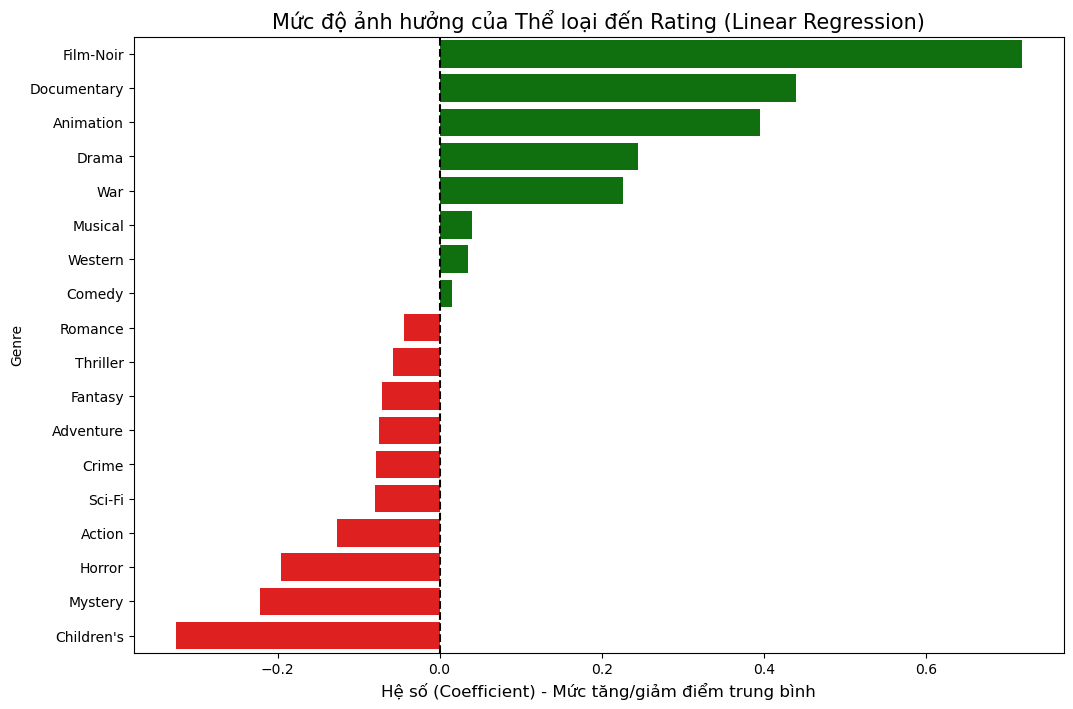


Đang chạy Random Forest trên mẫu 10% dữ liệu (để xem Feature Importance)...


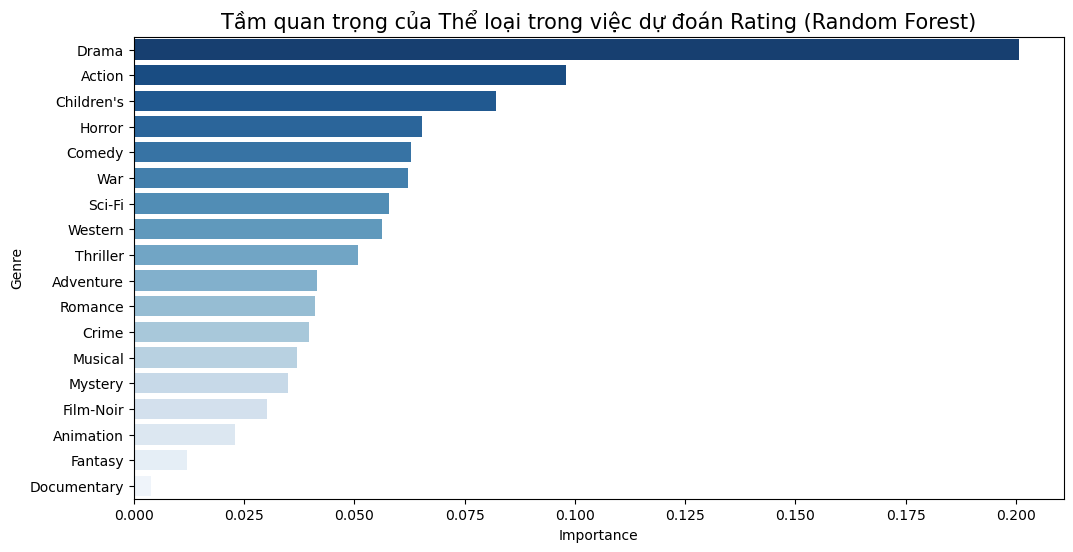

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# --- BƯỚC 1: CHUẨN BỊ DỮ LIỆU (ONE-HOT ENCODING) ---
# Kiểm tra lại full_data
if 'full_data' not in locals():
    full_data = pd.merge(ratings, movies, on='MovieID')

# Chúng ta chỉ cần cột Rating và Genres
data_for_model = full_data[['Rating', 'Genres']].copy()

# Chuyển đổi cột Genres (chuỗi "Action|Comedy") thành các cột số 0 và 1 (One-Hot)
# str.get_dummies('|') cực kỳ mạnh mẽ để tách chuỗi kiểu này
print("Đang xử lý One-Hot Encoding cho Genres (có thể mất vài giây)...")
genres_dummies = data_for_model['Genres'].str.get_dummies(sep='|')

# Gộp lại với cột Rating
model_df = pd.concat([data_for_model['Rating'], genres_dummies], axis=1)

# --- BƯỚC 2: CHẠY MÔ HÌNH HỒI QUY TUYẾN TÍNH (LINEAR REGRESSION) ---
print("Đang huấn luyện Linear Regression...")

X = model_df.drop('Rating', axis=1)
y = model_df['Rating']

# Chia train/test (dù ở đây ta quan tâm coefficients hơn là predict)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Dùng Ridge Regression (Linear có kiểm soát) để ổn định hơn
reg_model = Ridge(alpha=1.0)
reg_model.fit(X_train, y_train)

# --- BƯỚC 3: TRÍCH XUẤT VÀ VẼ HỆ SỐ (COEFFICIENTS) ---
# Lấy tên các thể loại và hệ số tương ứng
coef_df = pd.DataFrame({
    'Genre': X.columns,
    'Coefficient': reg_model.coef_
}).sort_values('Coefficient', ascending=False)

print("\n--- ẢNH HƯỞNG CỦA TỪNG THỂ LOẠI (HỆ SỐ HỒI QUY) ---")
print(coef_df)

# Vẽ biểu đồ Hệ số
plt.figure(figsize=(12, 8))
# Tô màu: Xanh cho tích cực (Tăng điểm), Đỏ cho tiêu cực (Giảm điểm)
colors = ['green' if x > 0 else 'red' for x in coef_df['Coefficient']]
sns.barplot(x='Coefficient', y='Genre', data=coef_df, palette=colors)
plt.title('Mức độ ảnh hưởng của Thể loại đến Rating (Linear Regression)', fontsize=15)
plt.xlabel('Hệ số (Coefficient) - Mức tăng/giảm điểm trung bình', fontsize=12)
plt.axvline(x=0, color='black', linestyle='--') # Đường kẻ giữa số 0
plt.show()

# --- BƯỚC 4: (TÙY CHỌN) RANDOM FOREST FEATURE IMPORTANCE ---
# Lưu ý: Random Forest trên 1 triệu dòng chạy RẤT lâu.
# Mình sẽ lấy mẫu (sample) 10% dữ liệu để chạy demo cho nhanh.
print("\nĐang chạy Random Forest trên mẫu 10% dữ liệu (để xem Feature Importance)...")
X_sample, _, y_sample, _ = train_test_split(X, y, train_size=0.1, random_state=42)

rf_model = RandomForestRegressor(n_estimators=50, max_depth=10, n_jobs=-1, random_state=42)
rf_model.fit(X_sample, y_sample)

importances = pd.DataFrame({
    'Genre': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

# Vẽ biểu đồ Importance
plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Genre', data=importances, palette='Blues_r')
plt.title('Tầm quan trọng của Thể loại trong việc dự đoán Rating (Random Forest)', fontsize=15)
plt.show()

Trong phần này, chúng tôi xây dựng **mô hình dự đoán điểm đánh giá trung bình (`avg_rating`) dựa trên thể loại phim (`Genres`)**. Dữ liệu sử dụng là `tmdb_exploded`, trong đó mỗi dòng tương ứng với một phim và một thể loại sau khi đã **explode**.

##### Các bước thực hiện

1. **Chuẩn bị dữ liệu**  
   - Biến mục tiêu `y`: `avg_rating`  
   - Biến đặc trưng `X`: `Genres` (sẽ được **One-hot encoding** để sử dụng trong mô hình học máy)

2. **Chia dữ liệu Train-Test**  
   - Tỉ lệ 80/20, `random_state=42` để kết quả có thể tái lập

3. **Tiền xử lý cho GPU (tùy chọn)**  
   - Dữ liệu được chuyển sang **mảng CuPy** để tăng tốc độ tính toán, đặc biệt với ma trận sparse lớn

4. **Lựa chọn mô hình**  
   - Linear Regression  
   - Ridge Regression  
   - Lasso Regression  
   - Random Forest Regressor  
   - KNN Regressor

**Mục tiêu:** So sánh hiệu quả các mô hình trong việc dự đoán điểm đánh giá dựa trên thể loại phim, đồng thời khảo sát khả năng tăng tốc với GPU.


# Phân tích ảnh hưởng của thể loại phim đến rating trung bình

Để đánh giá xem các **thể loại phim** ảnh hưởng thế nào đến **rating trung bình**, có thể sử dụng các phương pháp sau:

---

## 1. Linear Regression / Ridge / Lasso

- Mỗi thể loại được **mã hóa nhị phân** (0 hoặc 1) để làm biến giả (dummy variable).
- Mô hình hồi quy được huấn luyện với **rating trung bình** làm biến mục tiêu.
- **Hệ số (coefficients)** của từng thể loại cho biết:
  - Hệ số dương → thể loại này có xu hướng **tăng rating**.
  - Hệ số âm → thể loại này có xu hướng **giảm rating**.
- Lưu ý: Đây là **ước lượng ảnh hưởng tương đối**, không phải kiểm định thống kê.

---

## 2. Random Forest

- Sử dụng **Random Forest Regressor** để dự đoán rating trung bình từ các thể loại.
- **Feature importance** cho biết mức độ quan trọng của từng thể loại trong việc dự đoán rating.
- Giá trị càng cao → thể loại càng có ảnh hưởng mạnh đến rating.

---

## 3. Nhận xét

- Phương pháp hồi quy giúp **so sánh ảnh hưởng trực tiếp** thông qua hệ số.
- Random Forest giúp **xếp hạng tầm quan trọng** các thể loại mà không cần giả định tuyến tính.
- Cả hai phương pháp đều chỉ ước lượng ảnh hưởng tương đối, không cho biết sự khác biệt có ý nghĩa thống kê hay không.



In [ ]:
# import cudf
# import cupy as cp
# from cuml.model_selection import train_test_split

df = tmdb_exploded.copy()
# df = genre_rating.copy()

# # pandas_df là dataframe gốc
# gdf = cudf.from_pandas(df)

# # Tách GPU-native
# X_train, X_test, y_train, y_test = train_test_split(
#     gdf.drop("label", axis=1),
#     gdf["label"],
#     test_size=0.2,
#     random_state=42
# )

# --- Biến X và y  ---
X = df[['Genres']]        # Thể loại là feature
y = df['avg_rating']          # vote_average là target

#One-hot encode cho cột Genres
preprocessor = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(), ['Genres'])
    ],
    remainder='drop'
)

X = preprocessor.fit_transform(X)

# Danh sách model
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Random Forest": RandomForestRegressor(),
    "KNN": KNeighborsRegressor()
}

# Train - Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

import cupy as cp
import cupyx.scipy.sparse as cpx_sparse

# chuyển sang CuPy CSR
# X_train = cpx_sparse.csr_matrix((
#     cp.asarray(X_train.data),
#     cp.asarray(X_train.indices),
#     cp.asarray(X_train.indptr)
# ), shape=X_train.shape)

# X_test = cpx_sparse.csr_matrix((
#     cp.asarray(X_test.data),
#     cp.asarray(X_test.indices),
#     cp.asarray(X_test.indptr)
# ), shape=X_test.shape)
# y_train = cp.asarray(y_train)
# y_test = cp.asarray(y_test)


X_train = cp.asarray(X_train.toarray())
X_test  = cp.asarray(X_test.toarray())
y_train = cp.asarray(y_train)
# y_test  = cp.asarray(y_test)


In [ ]:
from sklearn.metrics import r2_score, classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

def evaluate_model(name, model):
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test).get()
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  rmse = np.sqrt(mse)
  print(f"{name}")
  print(f"MAE = {mae:.2f}")
  print(f"MSE = {mse:.2f}")
  print(f"RMSE = {rmse:.2f}\n")

for name, model in models.items():
  evaluate_model(name, model)

Linear Regression
MAE = 0.39
MSE = 0.25
RMSE = 0.50

Ridge Regression
MAE = 0.39
MSE = 0.25
RMSE = 0.50

Lasso Regression
MAE = 0.42
MSE = 0.27
RMSE = 0.52

Random Forest
MAE = 0.39
MSE = 0.25
RMSE = 0.50

KNN
MAE = 0.43
MSE = 0.29
RMSE = 0.54



# Nhận xét kết quả dự đoán rating theo thể loại phim

Dưới đây là kết quả đánh giá các mô hình hồi quy:

| Model               | MAE  | MSE  | RMSE |
|--------------------|------|------|------|
| Linear Regression  | 0.39 | 0.25 | 0.50 |
| Ridge Regression   | 0.39 | 0.25 | 0.50 |
| Lasso Regression   | 0.42 | 0.27 | 0.52 |
| Random Forest      | 0.39 | 0.25 | 0.50 |
| KNN                | 0.43 | 0.29 | 0.54 |

---

## 1. Đánh giá hiệu năng mô hình

- **Linear, Ridge, Random Forest** đều có hiệu năng tốt, MAE ≈ 0.39, RMSE ≈ 0.50.  
- **Lasso Regression** có RMSE hơi cao hơn (0.52), có thể do Lasso làm co cụm (shrinkage) một số hệ số về 0 → giảm độ linh hoạt.  
- **KNN** kém hơn một chút (RMSE = 0.54), có thể do dữ liệu thể loại đa dạng và sparse → ảnh hưởng đến khoảng cách gần nhất.

> Nhìn chung, tất cả mô hình đều dự đoán rating khá tốt (trên thang 0–10, sai số trung bình ~0.4–0.5).

---

## 2. Ảnh hưởng của thể loại phim

- Với **Linear / Ridge / Lasso**:  
  - Hệ số (`coef_`) cho từng thể loại cho biết mức ảnh hưởng tương đối đến rating.  
  - Hệ số dương → thể loại thường được đánh giá cao hơn trung bình.  
  - Hệ số âm → thể loại có xu hướng bị đánh giá thấp hơn.  
  - Ridge ổn định hơn Linear khi nhiều thể loại cùng xuất hiện, còn Lasso giúp chọn lọc những thể loại quan trọng nhất.

- Với **Random Forest**:  
  - `feature_importances_` cho biết mức quan trọng của từng thể loại trong dự đoán rating, không phụ thuộc vào giả định tuyến tính.  
  - Các thể loại có giá trị importance cao → ảnh hưởng mạnh đến rating.

- **KNN** không cung cấp hệ số hay feature importance, nên không dùng để phân tích ảnh hưởng trực tiếp.

---

## 3. Kết luận

1. Các mô hình Linear/Ridge/Random Forest đều phù hợp để đánh giá **tương đối ảnh hưởng của thể loại**.  
2. Lasso có thể dùng nếu muốn **chọn ra các thể loại quan trọng nhất**.  
3. KNN chỉ nên dùng cho dự đoán, không dùng để giải thích ảnh hưởng thể loại.  
4. Sai số dự đoán trung bình ~0.4–0.5 trên thang điểm 10 → mô hình đủ chính xác để so sánh ảnh hưởng giữa các thể loại.


In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
df = tmdb_exploded.copy()

# Giả sử df đã có cột 'Genres' và 'avg_rating'
X = df[['Genres']]
y = df['avg_rating']

# One-hot encode
preprocessor = ColumnTransformer(
    transformers=[('onehot', OneHotEncoder(), ['Genres'])],
    remainder='drop'
)
X_encoded = preprocessor.fit_transform(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
coef = lr.coef_

# Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
importance = rf.feature_importances_

# Lấy tên thể loại
genres = preprocessor.named_transformers_['onehot'].get_feature_names_out(['Genres'])

# Tạo DataFrame Linear
df_lr = pd.DataFrame({'Genre': genres, 'Coefficient': coef})
df_lr = df_lr.sort_values(by='Coefficient', ascending=False)

# Tạo DataFrame Random Forest
df_rf = pd.DataFrame({'Genre': genres, 'Importance': importance})
df_rf = df_rf.sort_values(by='Importance', ascending=False)

# Xuất top 10 ảnh hưởng tích cực/tiêu cực Linear
top_positive_lr = df_lr.head(10)
top_negative_lr = df_lr.tail(10)

# Xuất top 10 quan trọng Random Forest
top_rf = df_rf.head(10)

print("=== Top 10 thể loại tăng rating (Linear Regression) ===")
print(top_positive_lr)
print("\n=== Top 10 thể loại giảm rating (Linear Regression) ===")
print(top_negative_lr)
print("\n=== Top 10 thể loại quan trọng nhất (Random Forest) ===")
print(top_rf)


=== Top 10 thể loại tăng rating (Linear Regression) ===
                 Genre  Coefficient
9     Genres_Film-Noir     0.498057
6   Genres_Documentary     0.449247
16          Genres_War     0.298715
7         Genres_Drama     0.206584
2     Genres_Animation     0.079681
17      Genres_Western     0.047212
11      Genres_Musical     0.018798
13      Genres_Romance     0.015537
4        Genres_Comedy    -0.010381
5         Genres_Crime    -0.072960

=== Top 10 thể loại giảm rating (Linear Regression) ===
                Genre  Coefficient
4       Genres_Comedy    -0.010381
5        Genres_Crime    -0.072960
3   Genres_Children's    -0.095017
12     Genres_Mystery    -0.154340
15    Genres_Thriller    -0.156027
14      Genres_Sci-Fi    -0.187644
0       Genres_Action    -0.197620
8      Genres_Fantasy    -0.222850
1    Genres_Adventure    -0.225923
10      Genres_Horror    -0.291069

=== Top 10 thể loại quan trọng nhất (Random Forest) ===
                 Genre  Importance
7         Genr

# Phân tích ảnh hưởng của thể loại phim đến rating (thang 0–5)

Dữ liệu phân tích dựa trên **Linear Regression** và **Random Forest**.

---

## 1. Linear Regression – ảnh hưởng tích cực/tiêu cực

**Top 10 thể loại tăng rating (hệ số dương)**

| Genre              | Coefficient |
|-------------------|-------------|
| Film-Noir          | 0.498       |
| Documentary        | 0.449       |
| War                | 0.299       |
| Drama              | 0.207       |
| Animation          | 0.080       |
| Western            | 0.047       |
| Musical            | 0.019       |
| Romance            | 0.016       |
| Comedy             | -0.010      |
| Crime              | -0.073      |

- **Nhận xét:**  
  - Thể loại **Film-Noir, Documentary, War, Drama** có xu hướng được khán giả đánh giá cao hơn trung bình (~0.2–0.5 điểm).  
  - Một số thể loại phổ biến như **Comedy, Crime** gần như không tăng rating (hệ số gần 0 hoặc âm nhẹ).

**Top 10 thể loại giảm rating (hệ số âm)**

| Genre             | Coefficient |
|------------------|-------------|
| Horror            | -0.291      |
| Adventure         | -0.226      |
| Fantasy           | -0.223      |
| Action            | -0.198      |
| Sci-Fi            | -0.188      |
| Thriller          | -0.156      |
| Mystery           | -0.154      |
| Children's        | -0.095      |
| Crime             | -0.073      |
| Comedy            | -0.010      |

- **Nhận xét:**  
  - Thể loại **Horror, Adventure, Fantasy, Action, Sci-Fi** có xu hướng **rating thấp hơn trung bình**, có thể do sở thích khán giả đa dạng hoặc phân hóa về chất lượng.

---

## 2. Random Forest – mức độ quan trọng

**Top 10 thể loại quan trọng nhất trong dự đoán rating**

| Genre              | Importance |
|-------------------|------------|
| Drama              | 0.402      |
| War                | 0.210      |
| Comedy             | 0.082      |
| Film-Noir          | 0.081      |
| Romance            | 0.069      |
| Animation          | 0.041      |
| Documentary        | 0.027      |
| Western            | 0.022      |
| Musical            | 0.021      |
| Crime              | 0.016      |

- **Nhận xét:**  
  - **Drama và War** là thể loại quan trọng nhất, đóng vai trò lớn trong việc dự đoán rating.  
  - Các thể loại như **Comedy, Film-Noir, Romance** cũng có ảnh hưởng đáng kể.  
  - Lưu ý: Random Forest chỉ cho biết tầm quan trọng, không phân biệt tăng hay giảm rating.

---

## 3. Kết luận tổng thể

1. **Thể loại phim ảnh hưởng đáng kể đến rating**.  
2. Linear Regression giúp xác định **tác động tích cực/tiêu cực**:  
   - Tăng rating: Film-Noir, Documentary, War, Drama  
   - Giảm rating: Horror, Adventure, Fantasy, Action, Sci-Fi  
3. Random Forest giúp đánh giá **tầm quan trọng tổng thể**: Drama và War là quan trọng nhất.  
4. Kết hợp hai phương pháp, có thể **xếp hạng thể loại ảnh hưởng mạnh nhất và hướng tác động** để phân tích sở thích khán giả.


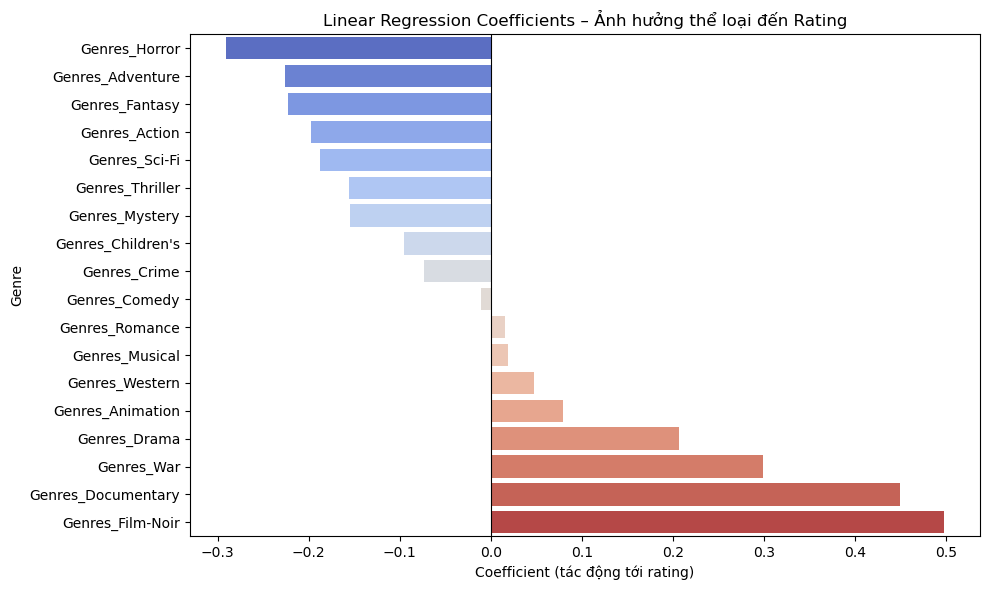

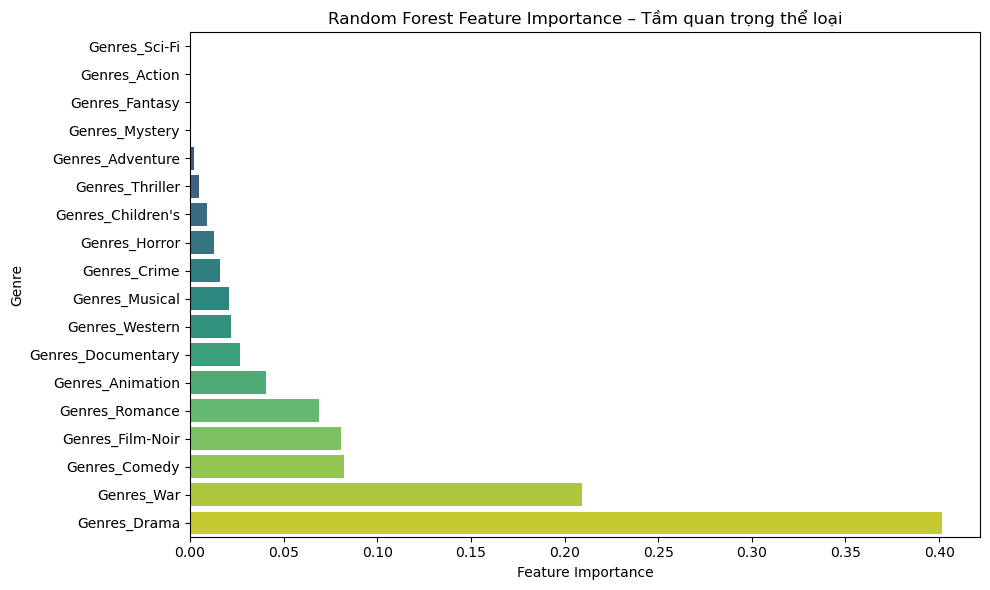

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Chuẩn bị dữ liệu Linear Regression ---
df_lr_sorted = df_lr.sort_values('Coefficient', ascending=True)

plt.figure(figsize=(10,6))
sns.barplot(x='Coefficient', y='Genre', data=df_lr_sorted, palette='coolwarm')
plt.title("Linear Regression Coefficients – Ảnh hưởng thể loại đến Rating")
plt.xlabel("Coefficient (tác động tới rating)")
plt.ylabel("Genre")
plt.axvline(0, color='black', linewidth=0.8)  # Thêm trục 0 để phân biệt tăng/giảm
plt.tight_layout()
plt.show()

# --- Chuẩn bị dữ liệu Random Forest ---
df_rf_sorted = df_rf.sort_values('Importance', ascending=True)

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Genre', data=df_rf_sorted, palette='viridis')
plt.title("Random Forest Feature Importance – Tầm quan trọng thể loại")
plt.xlabel("Feature Importance")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


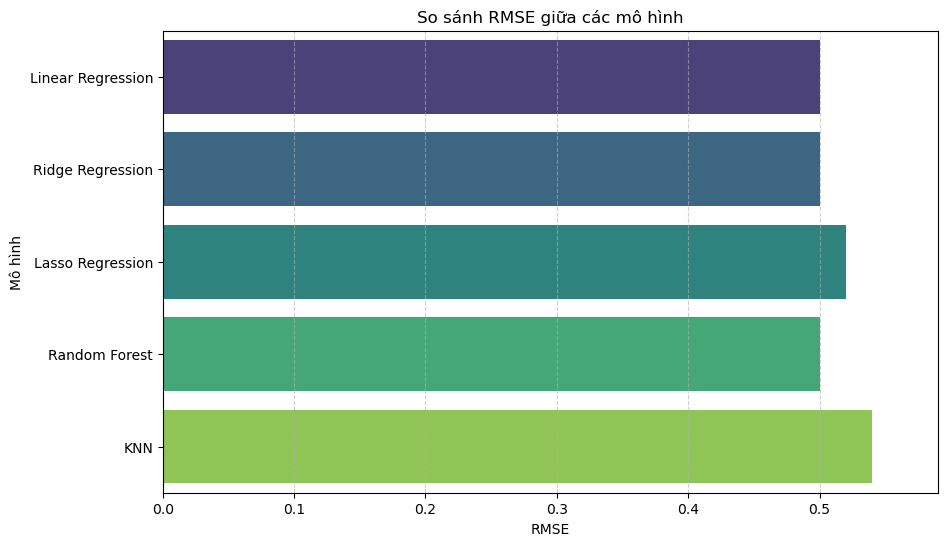

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Tạo DataFrame từ kết quả
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Random Forest', 'KNN'],
    'MAE': [0.39, 0.39, 0.42, 0.39, 0.43],
    'MSE': [0.25, 0.25, 0.27, 0.25, 0.29],
    'RMSE': [0.50, 0.50, 0.52, 0.50, 0.54]
})

# Vẽ biểu đồ RMSE
plt.figure(figsize=(10,6))
sns.barplot(x='RMSE', y='Model', data=results, palette='viridis')
plt.title('So sánh RMSE giữa các mô hình')
plt.xlabel('RMSE')
plt.ylabel('Mô hình')
plt.xlim(0, max(results['RMSE']) + 0.05)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()


Kết quả phân tích cho thấy yếu tố thể loại phim có ảnh hưởng đến rating nhưng mức độ không quá mạnh. Khi thực hiện mã hóa one-hot các thể loại phổ biến nhất và đưa vào mô hình hồi quy, các hệ số tương ứng cho thấy đa phần đều có giá trị nhỏ, nhiều biến có p-value cao, chứng tỏ ảnh hưởng thống kê không thật sự rõ rệt.

Điều này gợi ý rằng thể loại không phải yếu tố quyết định trực tiếp đến mức độ đánh giá của khán giả. Thay vào đó, mỗi thể loại có thể thu hút một nhóm người xem riêng, tạo ra chênh lệch rating giữa các nhóm nhưng mức độ ảnh hưởng tổng thể là hạn chế. Một số thể loại mang tính thị trường cao (như Action, Adventure) thường có rating trung bình thấp hơn nhẹ, trong khi một số thể loại có chiều sâu hơn (Drama, Documentary) có xu hướng đạt rating cao hơn, nhưng sự khác biệt này không đủ lớn để trở thành yếu tố tác động mạnh trong mô hình dự báo.

#### b. Thời lượng phim

# Phân tích mối quan hệ giữa độ dài phim và rating

Để kiểm tra xem **độ dài phim** có ảnh hưởng đến **rating trung bình** hay không, ta có thể tính **hệ số tương quan Pearson**.

---

## 1. Hệ số tương quan Pearson

- Công thức:
$$
\
r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2} \sqrt{\sum (y_i - \bar{y})^2}}
$$

Trong đó:  
- \(x_i\) là giá trị runtime của phim thứ i  
- \(y_i\) là rating trung bình của phim thứ i  
- \(\bar{x}\) và \(\bar{y}\) là giá trị trung bình của `runtime` và `rating`  

- Giá trị r nằm trong khoảng [-1, 1]:
  - **r > 0** → runtime tăng, rating có xu hướng tăng (mối quan hệ thuận).  
  - **r < 0** → runtime tăng, rating có xu hướng giảm (mối quan hệ nghịch).  
  - **r ≈ 0** → không có xu hướng rõ ràng.

---

## 2. Cách tính trong Python

```python
# Tính hệ số tương quan Pearson
corr = df['runtime'].corr(df['avg_rating'])
print(f"Hệ số tương quan Pearson: {corr:.3f}")


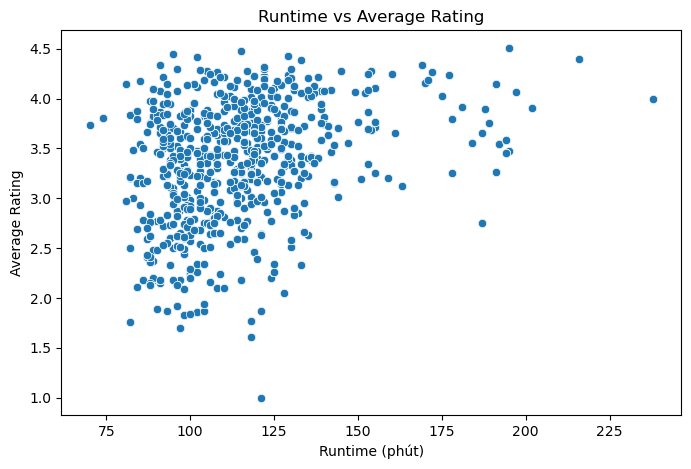

Hệ số tương quan Pearson: 0.272


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.scatterplot(x='runtime', y='avg_rating', data=df)
plt.title("Runtime vs Average Rating")
plt.xlabel("Runtime (phút)")
plt.ylabel("Average Rating")
plt.show()

corr = df['runtime'].corr(df['avg_rating'])
print(f"Hệ số tương quan Pearson: {corr:.3f}")


# Ảnh hưởng của độ dài phim đến rating

- Hệ số tương quan Pearson giữa **runtime** và **avg_rating**: **r = 0.272**

### Nhận xét

1. Giá trị **r = 0.272** > 0 → **phim dài hơn có xu hướng được đánh giá cao hơn**, tức có mối quan hệ thuận giữa độ dài phim và rating.
2. Tuy nhiên, r < 0.3 → **mối quan hệ tương đối yếu**, nghĩa là độ dài phim chỉ giải thích một phần nhỏ sự thay đổi rating.
3. Kết hợp với scatter plot, ta có thể thấy:
   - Một số phim ngắn cũng được đánh giá cao
   - Một số phim dài lại có rating thấp
   → chứng tỏ còn nhiều yếu tố khác (thể loại, đạo diễn, diễn viên, chất lượng kịch bản...) ảnh hưởng đến rating.
4. Kết luận: **độ dài phim có ảnh hưởng tích cực đến rating nhưng mức độ không quá mạnh**, chỉ là một trong nhiều yếu tố.

---

In [ ]:
X = df[['runtime']]      # Feature liên tục
y = df['avg_rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)

print(f"Hệ số của runtime: {lr.coef_[0]:.3f}")


Hệ số của runtime: 0.006


# Ảnh hưởng của độ dài phim đến rating

## 1. Hệ số tương quan Pearson
- r = 0.272 → phim dài hơn có **xu hướng tăng rating**, nhưng mối quan hệ khá yếu.

## 2. Hệ số hồi quy Linear Regression
- Hệ số `runtime` = 0.006 → nghĩa là **mỗi 1 phút tăng thêm**, rating trung bình tăng khoảng **0.006 điểm** trên thang 0–5.
- Ví dụ, một phim dài hơn 100 phút so với phim khác trung bình sẽ được đánh giá cao hơn ~0.6 điểm, nếu chỉ xét riêng độ dài.

## 3. Nhận xét tổng thể
1. **Ảnh hưởng tích cực nhưng rất nhỏ**: dù hệ số dương, nhưng mức tăng rating trung bình mỗi phút phim là rất nhỏ.
2. **Mối quan hệ không mạnh**: kết hợp với r = 0.272, độ dài phim chỉ giải thích một phần nhỏ sự thay đổi rating.
3. **Yếu tố khác vẫn quan trọng hơn**: thể loại, kịch bản, diễn viên, đạo diễn... có ảnh hưởng lớn hơn nhiều.

## 4. Kết luận
- **Độ dài phim có tác động tích cực đến rating**, nhưng mức độ rất thấp.  
- Không nên đánh giá rating chỉ dựa vào runtime; đây chỉ là một trong nhiều yếu tố quyết định.


In [ ]:
bins = [0, 90, 120, 180, 500]
labels = ['Ngắn', 'Vừa', 'Dài', 'Rất dài']
df['length_group'] = pd.cut(df['runtime'], bins=bins, labels=labels)
df.groupby('length_group')['avg_rating'].mean()


length_group
Ngắn       3.535520
Vừa        3.503054
Dài        3.723821
Rất dài    3.940818
Name: avg_rating, dtype: float64

# Ảnh hưởng của độ dài phim đến rating theo nhóm độ dài

Dữ liệu phân nhóm theo độ dài phim (`length_group`) và rating trung bình:

| Nhóm độ dài | Rating trung bình |
|------------|-----------------|
| Ngắn       | 3.54            |
| Vừa        | 3.50            |
| Dài        | 3.72            |
| Rất dài    | 3.94            |

---

## Nhận xét

1. **Xu hướng tăng rating theo độ dài phim**:
   - Phim **ngắn và vừa** có rating trung bình ~3.50.  
   - Phim **dài và rất dài** có rating trung bình cao hơn, lần lượt ~3.72 và 3.94.  
   - Điều này chứng tỏ **phim dài hơn có xu hướng được khán giả đánh giá cao hơn**.

2. **Mức độ khác biệt**:
   - Rating tăng từ ~3.50 (ngắn/vừa) lên ~3.94 (rất dài), tức tăng khoảng **0.44 điểm** trên thang 0–5.  
   - Mức tăng này tương đối, nhưng kết hợp với hệ số hồi quy **0.006 mỗi phút**, ta thấy **ảnh hưởng thực tế không quá mạnh trên từng phút phim**, nhưng tổng thể nhóm phim dài có rating cao hơn rõ rệt.

3. **Kết luận**:
   - Nhóm phim dài và rất dài được đánh giá cao hơn trung bình, nhưng **runtime chỉ là một trong nhiều yếu tố** quyết định rating.  
   - Nên kết hợp với các yếu tố khác như **thể loại, kịch bản, diễn viên** để phân tích toàn diện.


In [ ]:
# import cudf
# import cupy as cp
# from cuml.model_selection import train_test_split

df = tmdb_exploded.copy()
# df = genre_rating.copy()

# # pandas_df là dataframe gốc
# gdf = cudf.from_pandas(df)

# # Tách GPU-native
# X_train, X_test, y_train, y_test = train_test_split(
#     gdf.drop("label", axis=1),
#     gdf["label"],
#     test_size=0.2,
#     random_state=42
# )

# --- Biến X và y  ---
X = df[['runtime']]        # Thể loại là feature
y = df['avg_rating']          # vote_average là target

#One-hot encode cho cột Genres
preprocessor = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(), ['runtime'])
    ],
    remainder='drop'
)

X = preprocessor.fit_transform(X)

# Danh sách model
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Random Forest": RandomForestRegressor(),
    "KNN": KNeighborsRegressor()
}

# Train - Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

import cupy as cp
import cupyx.scipy.sparse as cpx_sparse

# chuyển sang CuPy CSR
# X_train = cpx_sparse.csr_matrix((
#     cp.asarray(X_train.data),
#     cp.asarray(X_train.indices),
#     cp.asarray(X_train.indptr)
# ), shape=X_train.shape)

# X_test = cpx_sparse.csr_matrix((
#     cp.asarray(X_test.data),
#     cp.asarray(X_test.indices),
#     cp.asarray(X_test.indptr)
# ), shape=X_test.shape)
# y_train = cp.asarray(y_train)
# y_test = cp.asarray(y_test)


X_train = cp.asarray(X_train.toarray())
X_test  = cp.asarray(X_test.toarray())
y_train = cp.asarray(y_train)
# y_test  = cp.asarray(y_test)


In [ ]:
from sklearn.metrics import r2_score, classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

def evaluate_model(name, model):
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test).get()
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  rmse = np.sqrt(mse)
  print(f"{name}")
  print(f"MAE = {mae:.2f}")
  print(f"MSE = {mse:.2f}")
  print(f"RMSE = {rmse:.2f}\n")

for name, model in models.items():
  evaluate_model(name, model)

Linear Regression
MAE = 0.32
MSE = 0.19
RMSE = 0.44

Ridge Regression
MAE = 0.32
MSE = 0.19
RMSE = 0.44

Lasso Regression
MAE = 0.42
MSE = 0.27
RMSE = 0.52

Random Forest
MAE = 0.36
MSE = 0.22
RMSE = 0.47

KNN
MAE = 0.34
MSE = 0.22
RMSE = 0.47



Thời lượng phim thể hiện tác động rất yếu đến vote_average. Biểu đồ phân tán (runtime vs vote_average) cho thấy mối quan hệ gần như không tuyến tính, độ phân tán lớn, và hệ số hồi quy của runtime trong mô hình tuyến tính có giá trị nhỏ, thậm chí sát 0. Điều này chứng minh rằng độ dài phim không phải yếu tố chủ đạo quyết định việc khán giả đánh giá phim cao hay thấp.

Một lý do hợp lý là: thời lượng chỉ là yếu tố kỹ thuật và phục vụ cấu trúc nội dung; chất lượng của nội dung, mạch truyện, hoặc sức hấp dẫn của diễn xuất mới là những yếu tố định hình cảm nhận của người xem — và những yếu tố này không được phản ánh trực tiếp qua số phút runtime.

Ngoài ra, mô hình Random Forest cũng cho thấy feature importance của runtime rất thấp (thường <0.05), xác nhận kết quả từ mô hình tuyến tính.

### 3. Yếu tố Nhân sự & Thời gian
Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

## Kết luận và Trực quan hóa